# Proyecto Bloque 3 — Segmentación de clientes con clustering
**Dataset:** Online Retail II (UCI) — transacciones de un minorista online del Reino Unido, dic-2009 → dic-2011.
**Sin etiquetas:** no existe una segmentación "verdadera"; solo se usan métricas internas.

| Etapa | Espacio | Modelos | Métricas |
|---|---|---|---|
| 1 | Variables originales escaladas | K-Means · GMM | Silhouette ↑ · Davies-Bouldin ↓ · Calinski-Harabasz ↑ |
| 2 | PCA (obligatorio) + UMAP (opcional) | K-Means · GMM | ídem, en el espacio reducido **y** en el original |

**Por qué K-Means y GMM:** pertenecen a familias distintas (partición dura por centroides vs. modelo probabilístico de mezcla con asignación suave y covarianzas) y ambos implementan `predict()`, lo que permite evaluar de forma limpia sobre el conjunto de prueba.

**Índice:** 0. Configuración · 1. EDA · 2. Limpieza · 3. Ingeniería de variables · 4. División y escalado · 5. Etapa 1 · 6. Etapa 2 (PCA) · 7. UMAP (opcional) · 8. Visualización t-SNE · 9. Comparación final · 10. Experimentos complementarios · 11. Conclusiones

## 0. Configuración
Se fija una semilla única (`SEED=42`) y se importan los módulos del proyecto (`src/`), donde vive la lógica reutilizable para que este cuaderno se centre en el análisis.

In [1]:
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score

from src.config import *
from src.features import FEATURES, load_raw, quality_report, clean_transactions, build_customer_features, log_transform
from src.evaluation import (internal_metrics, search_kmeans, search_gmm, select_best, make_kmeans, make_gmm,
                            evaluate_model, profile_clusters, relabel_by_score, save_fig)
from src.plotting import set_style, PALETTE, SEQ_CMAP, DIV_CMAP, scatter_clusters

warnings.filterwarnings("ignore", category=FutureWarning)
set_style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
np.random.seed(SEED)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | SEED={SEED}")

Python 3.12.3 | pandas 3.1.1 | scikit-learn 1.9.1 | SEED=42


## 1. Análisis exploratorio (EDA)
### 1.1 Carga y estructura
Cada fila es **una línea de factura** (producto × factura), no un cliente. Esto condiciona todo el proyecto: habrá que agregar a nivel de cliente antes de hacer clustering.

In [2]:
raw = load_raw()
print(f"Filas: {raw.shape[0]:,} | Columnas: {raw.shape[1]}")
display(raw.head())
display(raw.dtypes.to_frame("dtype"))

Filas: 1,067,371 | Columnas: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,dtype
Invoice,str
StockCode,str
Description,str
Quantity,int64
InvoiceDate,datetime64[us]
Price,float64
CustomerID,float64
Country,str


In [3]:
print(f"Rango de fechas: {raw.InvoiceDate.min()} → {raw.InvoiceDate.max()}")
print(f"Facturas: {raw.Invoice.nunique():,} | Productos: {raw.StockCode.nunique():,} | "
      f"Clientes: {raw.CustomerID.nunique():,} | Países: {raw.Country.nunique()}")
display(raw[["Quantity", "Price"]].describe().T)

Rango de fechas: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
Facturas: 53,628 | Productos: 5,305 | Clientes: 5,942 | Países: 43


,count,mean,std,min,25%,50%,75%,max
Quantity,1067371.0,9.938898,172.705794,-80995.00,1.00,3.0,10.00,80995.0
Price,1067371.0,4.649388,123.553059,-53594.36,1.25,2.1,4.15,38970.0


### 1.2 Calidad de datos
Se cuantifican los problemas antes de decidir cómo tratarlos.

In [4]:
display(quality_report(raw))

,filas,%
Filas totales,1067371,100.00
Filas duplicadas,34335,3.22
Sin CustomerID,243007,22.77
Sin Description,4382,0.41
Cancelaciones (Invoice 'C…'),19494,1.83
Quantity < 0,22950,2.15
Quantity < 0 y NO cancelación,3457,0.32
Price == 0,6202,0.58
Price < 0,5,0.00
StockCode no-producto,5982,0.56


**Lectura:**
- **22,8 % sin `CustomerID`** → no se pueden asignar a un cliente; se eliminarán (es el único modo de construir perfiles por cliente).
- **3,2 % duplicadas** exactas → se eliminan.
- **Cancelaciones** (`Invoice` con prefijo `C`, `Quantity` < 0) → no son ruido: describen el comportamiento de devolución y se usarán como variable (`return_rate`).
- `Price` ≤ 0 y StockCodes que no son productos (portes, comisiones, ajustes, vales, pruebas) → se eliminan porque no representan compras.

In [5]:
nonprod = raw[raw.StockCode.str.match(NON_PRODUCT_REGEX)]
display(nonprod.groupby("StockCode").agg(filas=("Description", "size"), descripcion=("Description", "first"))
        .sort_values("filas", ascending=False).head(15))

,filas,descripcion
StockCode,,
POST,2122,POSTAGE
DOT,1446,DOTCOM POSTAGE
M,1421,Manual
C2,282,CARRIAGE
D,177,Discount
S,104,SAMPLES
BANK CHARGES,102,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,AMAZON FEE


### 1.3 Distribuciones univariadas
Se usan solo líneas de venta válidas (no canceladas, `Price` > 0). Escala logarítmica porque las colas son extremas.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


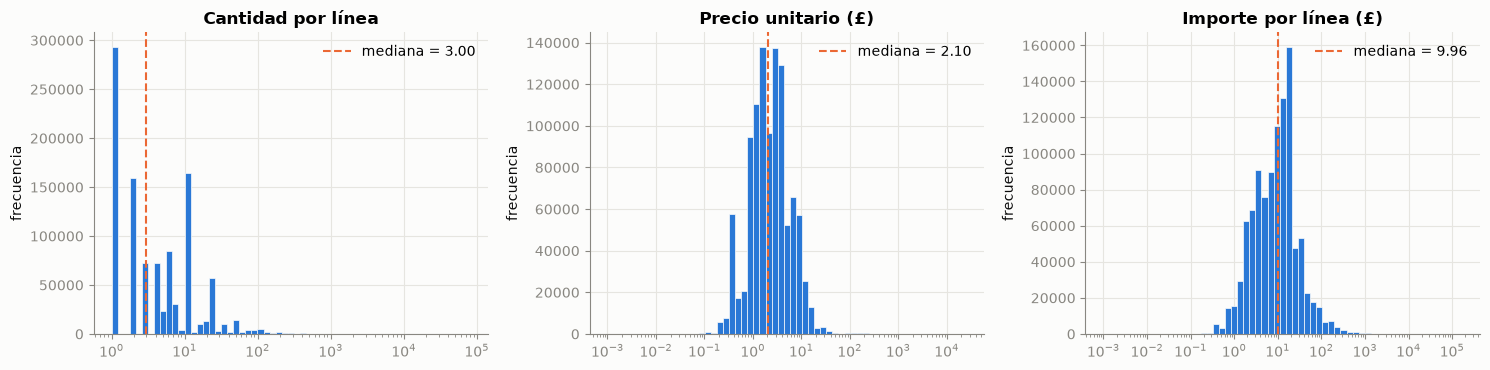

,0.500,0.900,0.990,0.999
Quantity,3.00,24.00,100.0,485.98600
Price,2.10,7.95,18.0,159.20331
amount,9.96,33.00,183.6,840.23832


In [6]:
sales_raw = raw[(~raw.Invoice.str.startswith("C")) & (raw.Price > 0) & (raw.Quantity > 0)].copy()
sales_raw["amount"] = sales_raw.Quantity * sales_raw.Price

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in zip(axes, ["Quantity", "Price", "amount"],
                          ["Cantidad por línea", "Precio unitario (£)", "Importe por línea (£)"]):
    v = sales_raw[col]
    ax.hist(v, bins=np.logspace(np.log10(v.min()), np.log10(v.max()), 60), color=PALETTE[0], edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_xscale("log"); ax.set_title(title); ax.set_ylabel("frecuencia")
    ax.axvline(v.median(), color=PALETTE[1], ls="--", lw=1.5, label=f"mediana = {v.median():.2f}")
    ax.legend()
plt.tight_layout(); save_fig(fig, "eda_distribuciones"); plt.show()
display(sales_raw[["Quantity", "Price", "amount"]].quantile([.5, .9, .99, .999]).T)

### 1.4 Patrones temporales

/tmp/ipykernel_53643/1896852851.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dow = sales_raw.groupby(sales_raw.InvoiceDate.dt.dayofweek)["Invoice"].nunique()


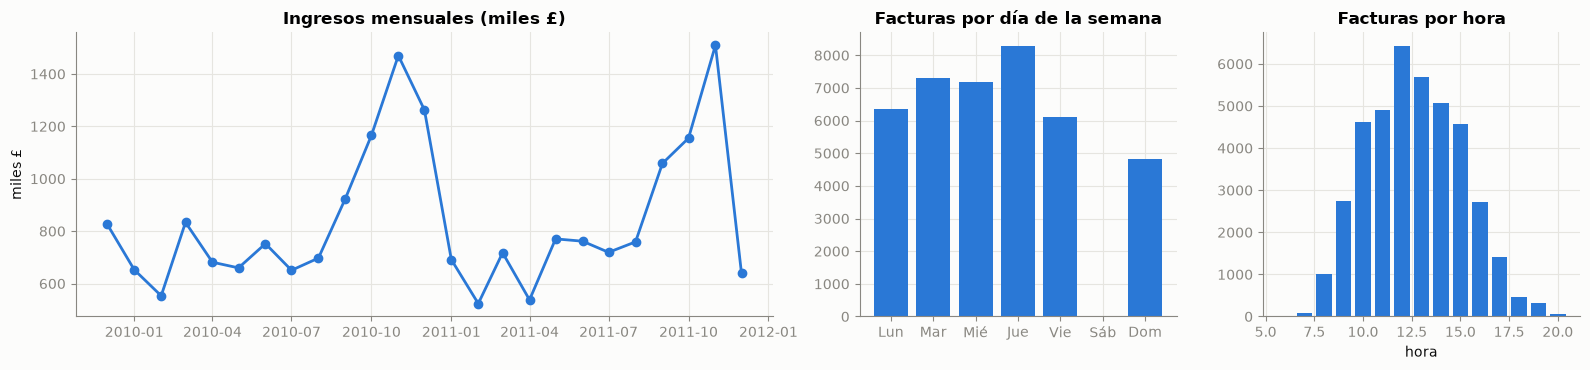

In [7]:
monthly = sales_raw.set_index("InvoiceDate").resample("MS")["amount"].sum() / 1e3
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.2, 1, 1]})
axes[0].plot(monthly.index, monthly.values, marker="o", color=PALETTE[0])
axes[0].set_title("Ingresos mensuales (miles £)"); axes[0].set_ylabel("miles £")
dow = sales_raw.groupby(sales_raw.InvoiceDate.dt.dayofweek)["Invoice"].nunique()
dow.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"][: len(dow)] if len(dow) == 7 else dow.index.map(dict(enumerate(["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"])))
axes[1].bar(dow.index, dow.values, color=PALETTE[0]); axes[1].set_title("Facturas por día de la semana")
hour = sales_raw.groupby(sales_raw.InvoiceDate.dt.hour)["Invoice"].nunique()
axes[2].bar(hour.index, hour.values, color=PALETTE[0]); axes[2].set_title("Facturas por hora"); axes[2].set_xlabel("hora")
plt.tight_layout(); save_fig(fig, "eda_temporal"); plt.show()

Fuerte **estacionalidad** (pico en oct–nov por compras navideñas) y actividad en horario laboral, casi nula en sábado: el perfil es de un mayorista/B2B que vende a minoristas, más que de consumidor final.

### 1.5 Geografía y productos

,ingresos,clientes,%ingresos
Country,,,
United Kingdom,1.787098e+07,5350,85.2
EIRE,6.644318e+05,5,3.2
Netherlands,5.542323e+05,22,2.6
Germany,4.312625e+05,107,2.1
France,3.569446e+05,95,1.7
Australia,1.699681e+05,15,0.8
Spain,1.091785e+05,41,0.5
Switzerland,1.010113e+05,22,0.5
Sweden,9.190372e+04,19,0.4


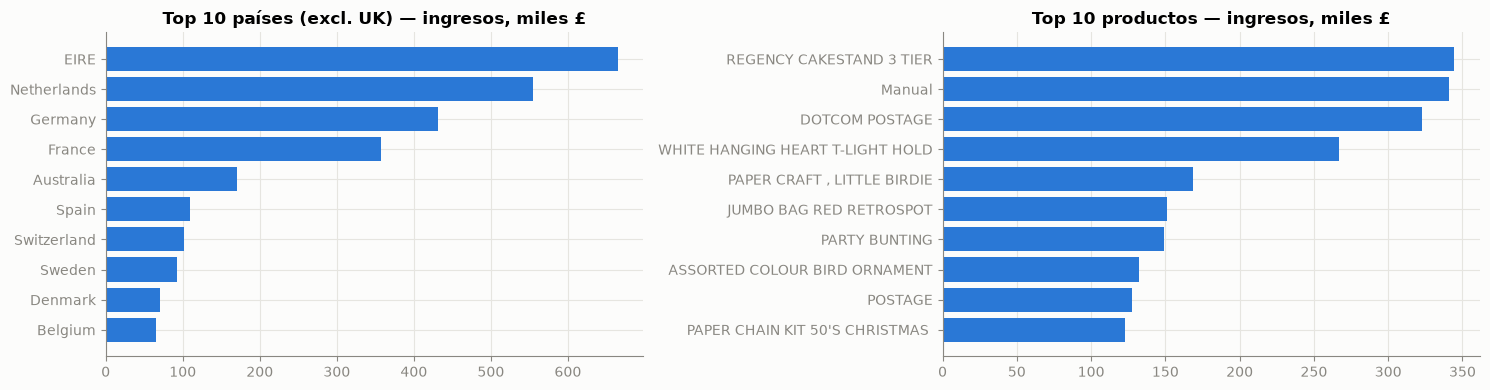

In [8]:
geo = sales_raw.groupby("Country").agg(ingresos=("amount", "sum"), clientes=("CustomerID", "nunique"))
geo["%ingresos"] = (geo.ingresos / geo.ingresos.sum() * 100).round(1)
display(geo.sort_values("ingresos", ascending=False).head(10))

top_prod = sales_raw.groupby("Description")["amount"].sum().nlargest(10).sort_values() / 1e3
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
g10 = geo.drop("United Kingdom").nlargest(10, "ingresos").sort_values("ingresos")
axes[0].barh(g10.index, g10.ingresos / 1e3, color=PALETTE[0]); axes[0].set_title("Top 10 países (excl. UK) — ingresos, miles £")
axes[1].barh(top_prod.index.str.slice(0, 32), top_prod.values, color=PALETTE[0]); axes[1].set_title("Top 10 productos — ingresos, miles £")
plt.tight_layout(); save_fig(fig, "eda_geo_productos"); plt.show()

### 1.6 Conclusiones del EDA
1. Los datos son **transaccionales** → la unidad de análisis será el **cliente** (agregación tipo RFM).
2. Variables con **colas muy pesadas** (cantidades y precios de mayorista) → habrá que aplicar `log1p` antes de escalar; K-Means y GMM son sensibles a la escala y a los valores extremos.
3. UK concentra la gran mayoría de clientes/ingresos → el país no se usará como variable de clustering (dominaría una dummy binaria), sí para perfilar.
4. Las cancelaciones aportan información de comportamiento → variable `return_rate`.

## 2. Limpieza
Los pasos se aplican en orden y se registra cuántas filas elimina cada uno (trazabilidad).

In [9]:
tx, clean_log = clean_transactions(raw)
display(clean_log)
print(f"Transacciones limpias: {len(tx):,} ({len(tx)/len(raw):.1%} del original) | clientes: {tx.CustomerID.nunique():,}")

,paso,filas_restantes,eliminadas
0,Inicial,1067371,0
1,- duplicados,1033036,34335
2,- sin CustomerID,797885,235151
3,- Price <= 0,797815,70
4,- StockCode no-producto,794165,3650
5,- signo Quantity incoherente,794165,0


Transacciones limpias: 794,165 (74.4% del original) | clientes: 5,875


## 3. Ingeniería de variables por cliente
Fecha de referencia = día siguiente a la última transacción del dataset (fecha del "snapshot"; es una constante global, no depende de train/test).

| Variable | Definición | Qué captura |
|---|---|---|
| `recency_days` | días desde la última compra | R de RFM — actividad reciente |
| `frequency` | n.º de facturas de compra | F de RFM |
| `monetary` | gasto neto (ventas − devoluciones) | M de RFM |
| `avg_ticket` | ventas brutas / facturas | tamaño de pedido en £ |
| `n_products` | StockCodes distintos | amplitud del surtido |
| `avg_items_per_invoice` | unidades / factura | volumen (mayorista vs minorista) |
| `tenure_days` | días desde la primera compra | antigüedad |
| `avg_days_between_purchases` | (última − primera) / (frecuencia − 1) | ritmo de recompra* |
| `return_rate` | facturas canceladas / total facturas | propensión a devolver |

\* Para clientes de **una sola compra** el intervalo no es observable; se imputa la antigüedad como cota inferior (observación censurada).

In [10]:
REF_DATE = raw.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
customers = build_customer_features(tx, REF_DATE)
customers[FEATURES + ["country"]].to_parquet(CUSTOMERS_PARQUET)
print(f"Fecha de referencia: {REF_DATE.date()} | clientes: {len(customers):,} | variables: {len(FEATURES)}")
print(f"Clientes de una sola compra: {(customers.frequency == 1).mean():.1%}")
display(customers[FEATURES].describe().T.round(2))

Fecha de referencia: 2011-12-10 | clientes: 5,833 | variables: 9
Clientes de una sola compra: 27.4%


,count,mean,std,min,25%,50%,75%,max
recency_days,5833.0,199.41,208.38,0.00,25.00,95.00,378.00,738.00
frequency,5833.0,6.27,12.77,1.00,1.00,3.00,7.00,373.00
monetary,5833.0,2805.00,13846.78,0.00,333.74,843.74,2179.76,578408.64
avg_ticket,5833.0,384.68,1256.53,2.95,176.62,278.25,410.58,84236.25
n_products,5833.0,82.41,116.62,1.00,19.00,45.00,104.00,2546.00
avg_items_per_invoice,5833.0,254.97,1467.26,1.00,92.50,155.00,260.00,87167.00
tenure_days,5833.0,473.99,223.00,0.00,312.00,529.00,667.00,738.00
avg_days_between_purchases,5833.0,171.37,182.80,0.00,45.50,90.86,233.00,738.00
return_rate,5833.0,0.11,0.16,0.00,0.00,0.00,0.20,0.80


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


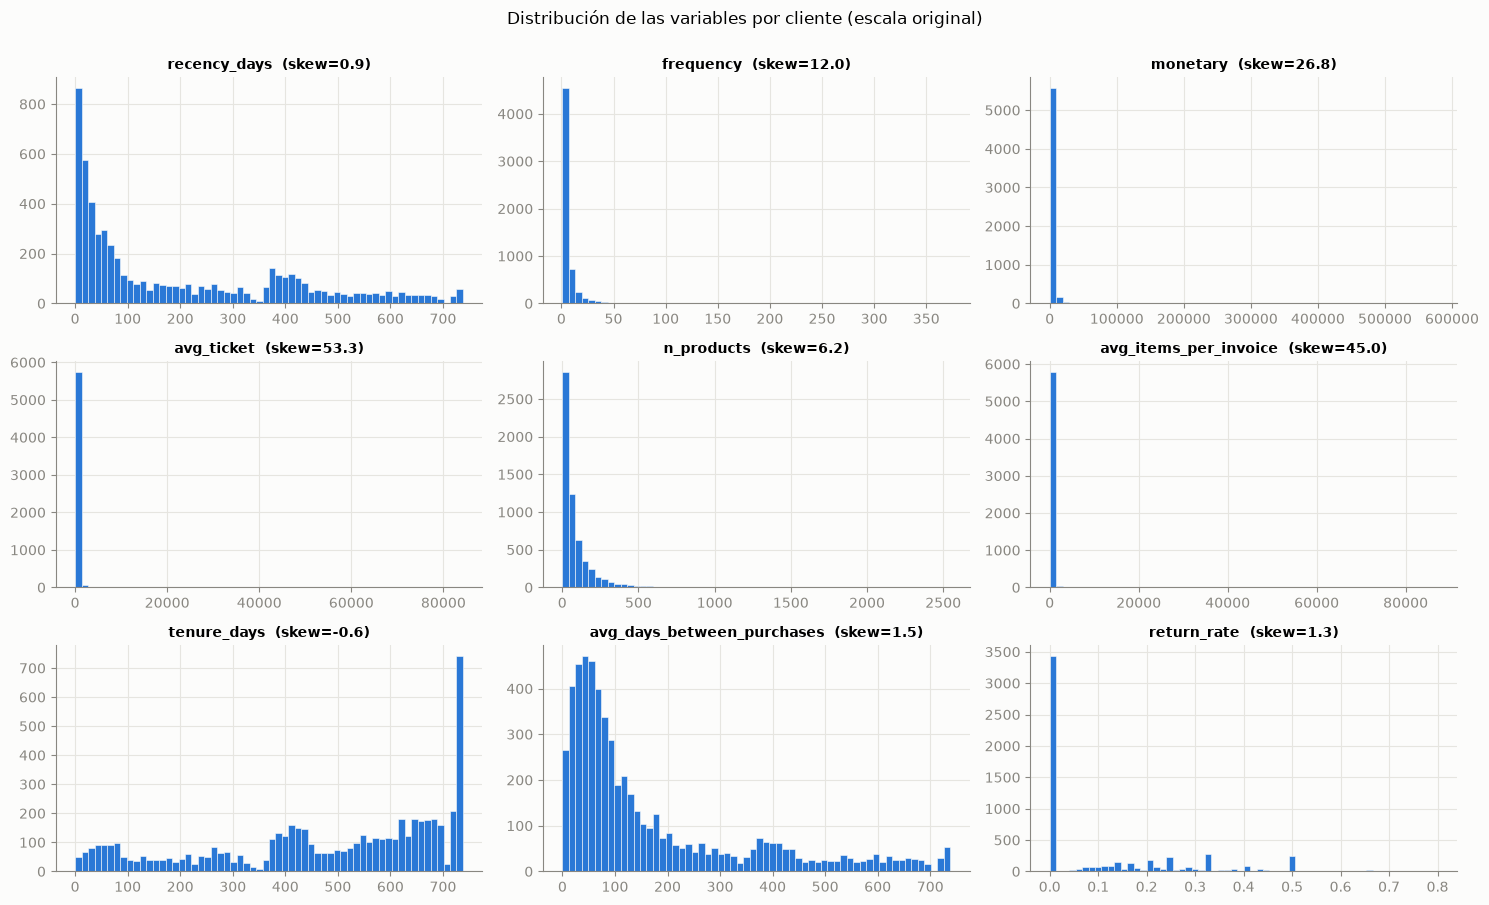

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.hist(customers[f], bins=60, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=0.4)
    ax.set_title(f"{f}  (skew={customers[f].skew():.1f})", fontsize=10)
plt.suptitle("Distribución de las variables por cliente (escala original)", y=1.0)
plt.tight_layout(); save_fig(fig, "features_hist_raw"); plt.show()

### 3.1 Valores extremos
Hay clientes mayoristas con gasto y volumen órdenes de magnitud superiores. **No se eliminan**: son clientes reales y relevantes para el negocio. En su lugar se reduce su influencia con `log1p` (siguiente sección). Se cuantifican con el criterio Q3 + 3·IQR.

In [12]:
q1, q3 = customers[FEATURES].quantile(.25), customers[FEATURES].quantile(.75)
extreme = (customers[FEATURES] > q3 + 3 * (q3 - q1)).sum()
display(extreme.to_frame("clientes_extremos (>Q3+3·IQR)"))
display(customers.nlargest(5, "monetary")[["country"] + FEATURES].round(1))

,clientes_extremos (>Q3+3·IQR)
recency_days,0
frequency,204
monetary,367
avg_ticket,157
n_products,156
avg_items_per_invoice,144
tenure_days,0
avg_days_between_purchases,0
return_rate,0


,country,recency_days,frequency,monetary,avg_ticket,n_products,avg_items_per_invoice,tenure_days,avg_days_between_purchases,return_rate
CustomerID,,,,,,,,,,
18102,United Kingdom,0,145,578408.6,4006.8,382,1252.7,738,5.1,0.0
14646,Netherlands,1,145,523202.7,3632.8,960,2531.5,737,5.1,0.0
14156,EIRE,9,144,297775.0,2104.7,1443,1140.8,738,5.1,0.2
14911,EIRE,1,373,258522.4,729.9,2546,396.3,738,2.0,0.2
17450,United Kingdom,8,51,233643.9,4799.7,144,1645.4,438,8.6,0.1


### 3.2 Correlaciones (tras `log1p`, para que no las dominen los extremos)

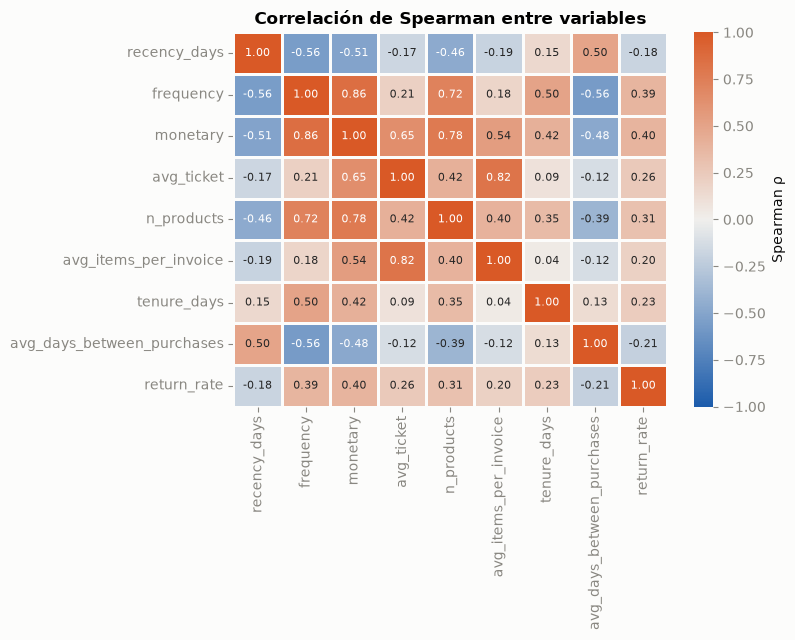

In [13]:
corr = np.log1p(customers[FEATURES]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ"},
            linewidths=2, linecolor="#fcfcfb", annot_kws={"size": 8})
ax.set_title("Correlación de Spearman entre variables"); plt.tight_layout(); save_fig(fig, "features_corr"); plt.show()

Hay **redundancia fuerte** (p. ej. `frequency`–`monetary`, `avg_ticket`–`avg_items_per_invoice`). Esto anticipa que PCA podrá comprimir el espacio sin perder mucha información (Etapa 2).

## 4. División entrenamiento/prueba, transformación y escalado
- División **por cliente**, 80/20, `random_state=SEED`. Cada fila se construyó solo con las transacciones de ese cliente, así que no hay fuga entre conjuntos.
- La decisión de qué variables llevan `log1p` (|skew| > 1) se toma **solo con train**. `return_rate` es una proporción acotada en [0,1] y se deja sin log.
- `StandardScaler` se **ajusta solo con train** y se aplica a ambos.

In [14]:
train_df, test_df = train_test_split(customers, test_size=TEST_SIZE, random_state=SEED)
skew_tr = train_df[FEATURES].skew()
LOG_COLS = [f for f in FEATURES if skew_tr[f] > 1 and f != "return_rate"]
print(f"train: {len(train_df):,} | test: {len(test_df):,}")
print("Variables con log1p:", LOG_COLS)

skew_cmp = pd.DataFrame({"skew_original": skew_tr,
                         "skew_tras_transformación": log_transform(train_df, LOG_COLS)[FEATURES].skew()}).round(2)
display(skew_cmp)

scaler = StandardScaler().fit(log_transform(train_df, LOG_COLS)[FEATURES])   # SOLO train
X_train = scaler.transform(log_transform(train_df, LOG_COLS)[FEATURES])
X_test = scaler.transform(log_transform(test_df, LOG_COLS)[FEATURES])

chk = pd.DataFrame({"media_train": X_train.mean(0), "std_train": X_train.std(0),
                    "media_test": X_test.mean(0), "std_test": X_test.std(0)}, index=FEATURES).round(3)
display(chk)

train: 4,666 | test: 1,167
Variables con log1p: ['frequency', 'monetary', 'avg_ticket', 'n_products', 'avg_items_per_invoice', 'avg_days_between_purchases']


,skew_original,skew_tras_transformación
recency_days,0.90,0.90
frequency,11.96,1.02
monetary,24.81,0.25
avg_ticket,48.49,0.18
n_products,6.54,-0.27
avg_items_per_invoice,40.60,-0.11
tenure_days,-0.62,-0.62
avg_days_between_purchases,1.49,-0.63
return_rate,1.30,1.30


,media_train,std_train,media_test,std_test
recency_days,-0.0,1.0,0.031,1.015
frequency,0.0,1.0,-0.064,0.959
monetary,-0.0,1.0,-0.052,0.945
avg_ticket,0.0,1.0,-0.014,0.938
n_products,0.0,1.0,-0.028,0.941
avg_items_per_invoice,0.0,1.0,-0.030,0.979
tenure_days,-0.0,1.0,-0.006,0.986
avg_days_between_purchases,-0.0,1.0,0.105,0.962
return_rate,0.0,1.0,-0.009,1.020


Train queda exactamente con media 0 y desviación 1; test se aproxima pero no es exacto → confirma que el escalador **no** vio los datos de prueba.

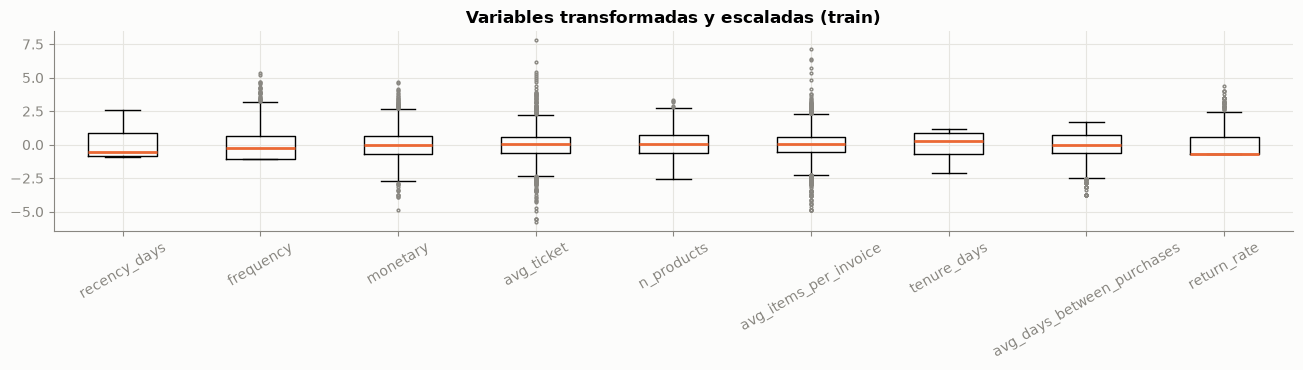

In [15]:
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.boxplot(X_train, tick_labels=FEATURES, flierprops={"markersize": 2, "markeredgecolor": "#898781"},
           medianprops={"color": PALETTE[1], "linewidth": 2})
ax.set_title("Variables transformadas y escaladas (train)"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig(fig, "features_scaled_box"); plt.show()

## 5. Etapa 1 — Clustering en el espacio original escalado (9 dimensiones)

**Regla de selección de hiperparámetros** (definida *antes* de mirar resultados y aplicada igual en todas las etapas):
1. Búsqueda en k ∈ [2, 10] (K-Means) y k ∈ [2, 10] × `covariance_type` ∈ {full, diag, tied, spherical} (GMM), **solo sobre train**.
2. Se descartan soluciones con algún cluster < 3 % de train (segmentos inútiles en la práctica).
3. Se consideran k ≥ 3: k = 2 suele maximizar las métricas internas pero solo separa "clientes de alto/bajo valor", lo que no aporta una segmentación accionable. Se reporta igualmente.
4. Se rankea Silhouette (↑), Davies-Bouldin (↓) y Calinski-Harabasz (↑) y se elige el **menor rango promedio**.

No hay etiquetas de referencia, así que ARI/NMI **no** se usan para elegir nada.

### 5.1 K-Means — búsqueda de k

In [16]:
t0 = time.perf_counter(); km1_res = search_kmeans(X_train); t_km1 = time.perf_counter() - t0
best_km1 = select_best(km1_res)
K_KM1 = int(best_km1.k)
display(km1_res.round(3).style.highlight_max(subset=["silhouette", "calinski_harabasz"], color="#cde2fb")
        .highlight_min(subset=["davies_bouldin"], color="#cde2fb"))
print(f"K-Means seleccionado: k={K_KM1} | búsqueda: {t_km1:.1f}s")

,k,inertia,min_cluster_frac,silhouette,davies_bouldin,calinski_harabasz
0,2,30396.968000,0.484000,0.246000,1.505000,1779.414000
1,3,25902.800000,0.262000,0.232000,1.550000,1448.366000
2,4,23131.678000,0.209000,0.194000,1.630000,1267.192000
3,5,21110.075000,0.123000,0.201000,1.531000,1152.792000
4,6,19433.427000,0.123000,0.188000,1.415000,1081.976000
5,7,18216.179000,0.090000,0.193000,1.432000,1013.578000
6,8,17279.215000,0.083000,0.187000,1.460000,951.775000
7,9,16371.483000,0.070000,0.193000,1.401000,911.072000
8,10,15613.210000,0.066000,0.178000,1.424000,874.116000


K-Means seleccionado: k=3 | búsqueda: 4.1s


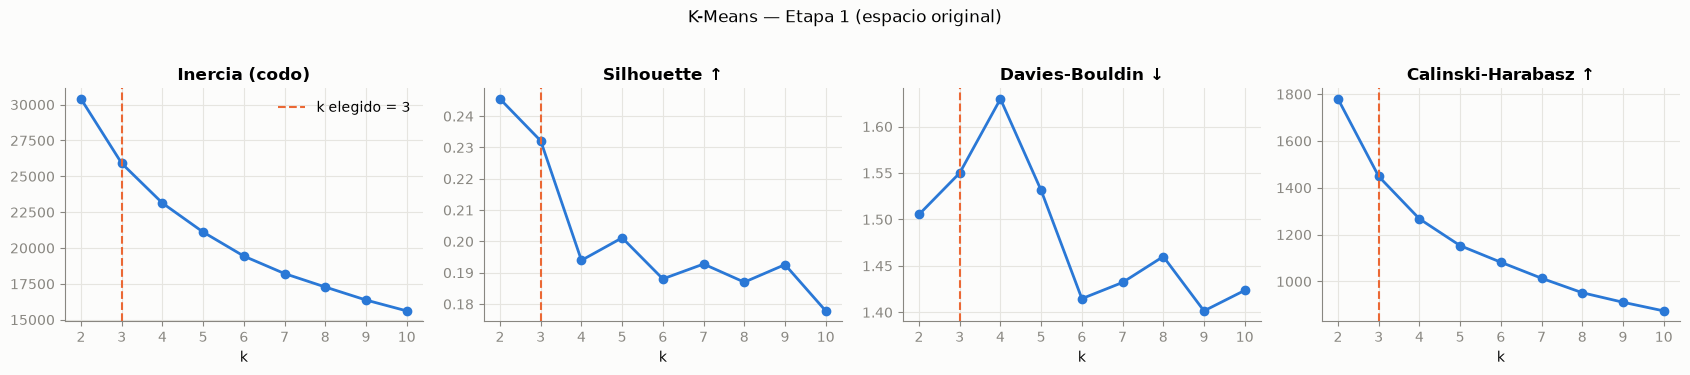

In [17]:
def plot_kmeans_search(res, k_sel, title, name):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, (col, lab) in zip(axes, [("inertia", "Inercia (codo)"), ("silhouette", "Silhouette ↑"),
                                     ("davies_bouldin", "Davies-Bouldin ↓"), ("calinski_harabasz", "Calinski-Harabasz ↑")]):
        ax.plot(res.k, res[col], marker="o", color=PALETTE[0])
        ax.axvline(k_sel, color=PALETTE[1], ls="--", lw=1.5, label=f"k elegido = {k_sel}")
        ax.set_title(lab); ax.set_xlabel("k"); ax.set_xticks(res.k)
    axes[0].legend(); fig.suptitle(title, y=1.03)
    plt.tight_layout(); save_fig(fig, name); plt.show()

plot_kmeans_search(km1_res, K_KM1, "K-Means — Etapa 1 (espacio original)", "e1_kmeans_search")

### 5.2 GMM — búsqueda de k y tipo de covarianza

In [18]:
t0 = time.perf_counter(); gm1_res = search_gmm(X_train); t_gm1 = time.perf_counter() - t0
best_gm1 = select_best(gm1_res)
K_GM1, COV_GM1 = int(best_gm1.k), best_gm1.covariance_type
display(gm1_res.sort_values("silhouette", ascending=False).head(10).round(3))
print(f"GMM seleccionado: k={K_GM1}, covariance_type='{COV_GM1}' | búsqueda: {t_gm1:.1f}s")

,k,covariance_type,bic,aic,n_used_clusters,min_cluster_frac,silhouette,davies_bouldin,calinski_harabasz
9,2,diag,107341.870,107103.292,2,0.457,0.235,1.544,1632.724
27,2,spherical,110847.882,110712.472,2,0.363,0.227,1.459,1594.985
28,3,spherical,107983.775,107777.437,3,0.204,0.213,1.555,1327.393
0,2,full,36778.100,36075.261,2,0.245,0.203,1.735,965.694
19,3,tied,78667.267,78190.111,3,0.267,0.198,1.675,1024.126
10,3,diag,102975.671,102614.580,3,0.280,0.178,1.800,1201.469
1,3,full,24656.550,23599.069,3,0.210,0.175,2.329,897.771
18,2,tied,81260.225,80847.549,2,0.427,0.171,1.902,1038.517
33,8,spherical,96823.201,96262.220,8,0.080,0.170,1.880,787.596
21,5,tied,77454.885,76848.768,5,0.123,0.169,1.575,903.082


GMM seleccionado: k=3, covariance_type='spherical' | búsqueda: 26.8s


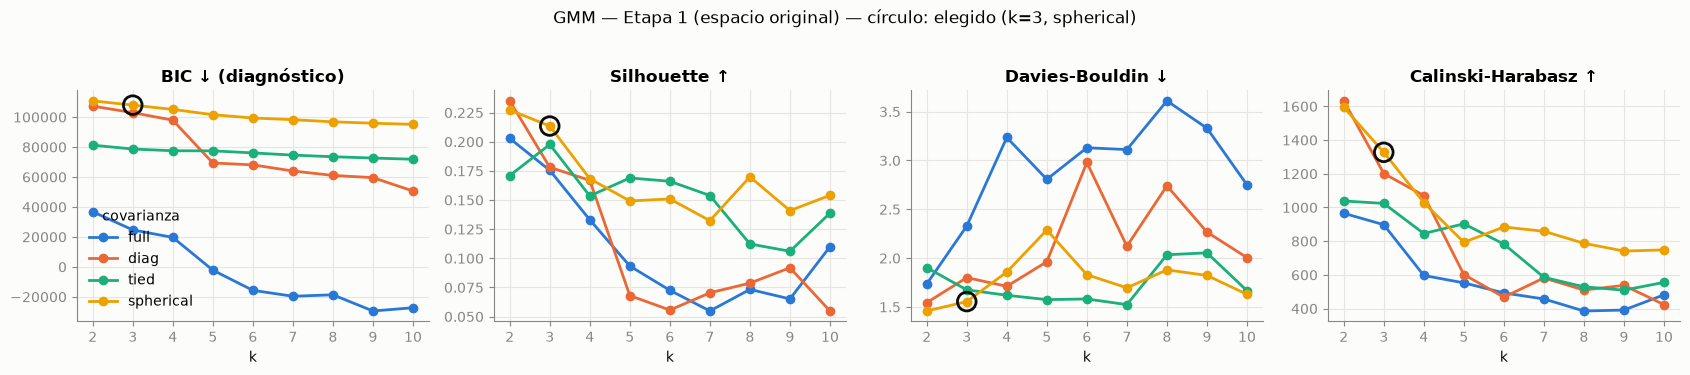

In [19]:
def plot_gmm_search(res, k_sel, cov_sel, title, name):
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, (col, lab) in zip(axes, [("bic", "BIC ↓ (diagnóstico)"), ("silhouette", "Silhouette ↑"),
                                     ("davies_bouldin", "Davies-Bouldin ↓"), ("calinski_harabasz", "Calinski-Harabasz ↑")]):
        for i, cov in enumerate(GMM_COV_TYPES):
            r = res[res.covariance_type == cov]
            ax.plot(r.k, r[col], marker="o", color=PALETTE[i], label=cov)
        sel = res[(res.k == k_sel) & (res.covariance_type == cov_sel)]
        ax.scatter(sel.k, sel[col], s=180, facecolors="none", edgecolors=TEXT_COLOR, linewidths=2, zorder=5)
        ax.set_title(lab); ax.set_xlabel("k"); ax.set_xticks(res.k.unique())
    axes[0].legend(title="covarianza"); fig.suptitle(f"{title} — círculo: elegido (k={k_sel}, {cov_sel})", y=1.03)
    plt.tight_layout(); save_fig(fig, name); plt.show()

TEXT_COLOR = "#0b0b0b"
plot_gmm_search(gm1_res, K_GM1, COV_GM1, "GMM — Etapa 1 (espacio original)", "e1_gmm_search")

**¿Por qué no se elige con BIC?** Con `covariance_type='full'` el BIC cae bruscamente a partir de k ≈ 5. Es un artefacto: en los clientes de **una sola compra** (~27 %) se cumple `recency = tenure = avg_days_between_purchases`, es decir, viven sobre un subespacio de menor dimensión. Una GMM con covarianza completa coloca ahí componentes casi degenerados (varianza ~0 en alguna dirección), la verosimilitud se dispara y el BIC deja de ser informativo. Por eso el BIC se muestra solo como diagnóstico y la selección usa las tres métricas internas, igual que para K-Means.

### 5.3 Modelos finales de la Etapa 1 — evaluación en train y test

In [20]:
kmeans1 = make_kmeans(K_KM1).fit(X_train)
gmm1 = make_gmm(K_GM1, COV_GM1).fit(X_train)

# Etiquetas canónicas para figuras/perfiles: 0 = segmento de mayor gasto neto medio.
# (las métricas no cambian: son invariantes a permutaciones de etiquetas)
canon = lambda lab: relabel_by_score(lab, X_train[:, FEATURES.index("monetary")])

def tag(df, modelo, etapa, espacio):
    return df.assign(modelo=modelo, etapa=etapa, espacio_modelo=espacio)

e1 = pd.concat([tag(evaluate_model(kmeans1, X_train, X_test), f"K-Means (k={K_KM1})", 1, "original"),
                tag(evaluate_model(gmm1, X_train, X_test), f"GMM (k={K_GM1}, {COV_GM1})", 1, "original")])
display(e1.set_index(["modelo", "conjunto"])[["silhouette", "davies_bouldin", "calinski_harabasz"]].round(3))

silhouette  davies_bouldin  calinski_harabasz
modelo               conjunto                                               
K-Means (k=3)        train          0.232           1.550           1448.366
                     test           0.231           1.530            364.164
GMM (k=3, spherical) train          0.213           1.555           1327.393
                     test           0.215           1.509            339.312

Las métricas en test son muy parecidas a las de train → las particiones **generalizan** a clientes no vistos (no son un artefacto de la muestra de entrenamiento).

### 5.4 Perfil de los segmentos (Etapa 1)
Se describen con **medianas en la escala original** (interpretables por negocio) y con un mapa de calor de medias estandarizadas (z) para comparar variables de distinta escala.

,n_clientes,%,recency_days,frequency,monetary,avg_ticket,n_products,avg_items_per_invoice,tenure_days,avg_days_between_purchases,return_rate
cluster,,,,,,,,,,,
0,1924,41.2,43.0,8.0,2763.2,358.0,116.0,210.7,652.0,67.6,0.1
1,1223,26.2,46.0,2.0,563.6,253.4,32.0,152.5,148.0,53.0,0.0
2,1519,32.6,409.0,1.0,309.8,187.0,19.0,100.0,551.0,347.0,0.0


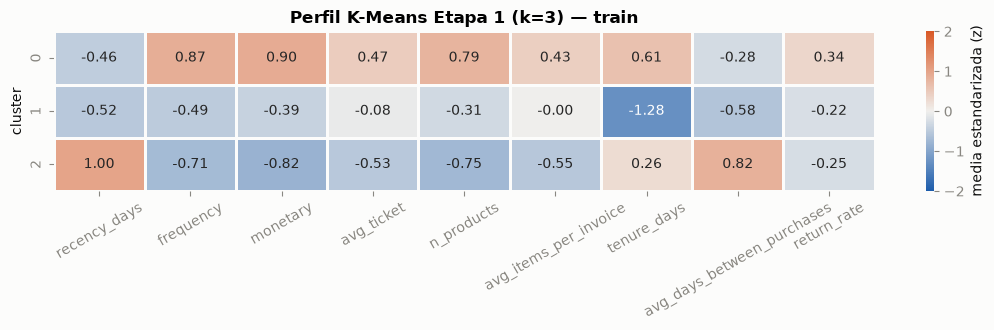

In [21]:
def show_profile(lab, df, title, name):
    # Perfil siempre en variables originales: medianas (escala real) + medias z (X_train escalado)
    prof = profile_clusters(df, lab, FEATURES)
    display(prof.round(1))
    z = pd.DataFrame(X_train, columns=FEATURES).groupby(lab).mean()
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(z) + 1.6))
    sns.heatmap(z, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, vmin=-2, vmax=2, ax=ax,
                linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "media estandarizada (z)"})
    ax.set_ylabel("cluster"); ax.set_title(title); ax.tick_params(axis="x", rotation=30)
    plt.tight_layout(); save_fig(fig, name); plt.show()
    return lab

lab_km1 = show_profile(canon(kmeans1.predict(X_train)), train_df, f"Perfil K-Means Etapa 1 (k={K_KM1}) — train", "e1_kmeans_profile")

,n_clientes,%,recency_days,frequency,monetary,avg_ticket,n_products,avg_items_per_invoice,tenure_days,avg_days_between_purchases,return_rate
cluster,,,,,,,,,,,
0,1848,39.6,38.0,8.0,2809.2,352.4,120.0,208.3,650.0,66.1,0.1
1,952,20.4,37.0,2.0,564.0,265.6,33.0,161.2,106.0,50.2,0.0
2,1866,40.0,394.0,2.0,341.7,197.0,20.0,106.0,528.0,276.0,0.0


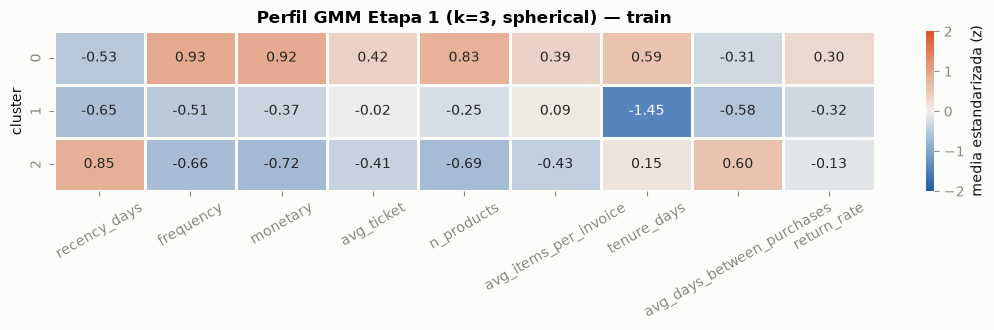

GMM: probabilidad posterior máxima media = 0.921 | clientes con asignación dudosa (<0.6): 5.9%
Concordancia K-Means vs GMM (ARI entre particiones, train): 0.779


In [22]:
lab_gm1 = show_profile(canon(gmm1.predict(X_train)), train_df, f"Perfil GMM Etapa 1 (k={K_GM1}, {COV_GM1}) — train", "e1_gmm_profile")
proba = gmm1.predict_proba(X_train).max(1)
print(f"GMM: probabilidad posterior máxima media = {proba.mean():.3f} | clientes con asignación dudosa (<0.6): {(proba < 0.6).mean():.1%}")
print(f"Concordancia K-Means vs GMM (ARI entre particiones, train): {adjusted_rand_score(lab_km1, lab_gm1):.3f}")

**Lectura de negocio de los 3 segmentos** (K-Means; la GMM produce los mismos tres perfiles con fronteras algo distintas):

| Cluster | Nombre propuesto | % train | Rasgos (medianas) | Acción sugerida |
|---|---|---|---|---|
| 0 | **Clientes leales de alto valor** | ~41 % | compra hace ~43 días, ~8 facturas, ~£2.760 de gasto, ~117 productos distintos, cliente desde hace ~650 días | fidelización, programa VIP, venta cruzada |
| 1 | **Clientes nuevos / en desarrollo** | ~26 % | activos recientemente (~46 días), pero solo ~2 facturas y ~150 días de antigüedad | onboarding, incentivar la 2.ª–3.ª compra |
| 2 | **Clientes inactivos / perdidos** | ~33 % | última compra hace ~410 días, 1 factura, gasto bajo (~£310) | campañas de reactivación de bajo coste o dar por perdidos |

`return_rate` casi no diferencia segmentos (mediana 0 en todos salvo los leales, que al comprar más también devuelven más).

La GMM aporta algo que K-Means no tiene: la **probabilidad de pertenencia**, que identifica clientes en la frontera entre segmentos. El ARI aquí no es validación externa (no hay etiquetas); solo mide cuánto coinciden las dos particiones.

## 6. Etapa 2 — Clustering en el espacio reducido con PCA
### 6.1 Ajuste de PCA (solo con train)
Se elige el número mínimo de componentes que explica ≥ 90 % de la varianza del train escalado.

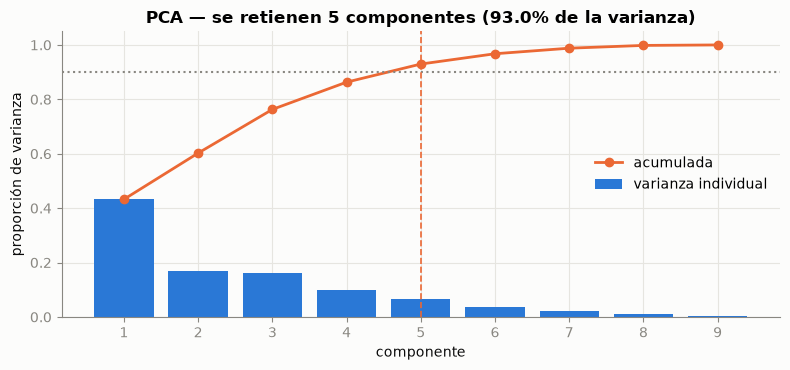

Dimensión: 9 → 5


In [23]:
pca_full = PCA(random_state=SEED).fit(X_train)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
N_PC = int(np.argmax(cumvar >= PCA_VAR_THRESHOLD) + 1)

fig, ax = plt.subplots(figsize=(8, 3.8))
comp = np.arange(1, len(cumvar) + 1)
ax.bar(comp, pca_full.explained_variance_ratio_, color=PALETTE[0], label="varianza individual")
ax.plot(comp, cumvar, marker="o", color=PALETTE[1], label="acumulada")
ax.axhline(PCA_VAR_THRESHOLD, color="#898781", ls=":", lw=1.5)
ax.axvline(N_PC, color=PALETTE[1], ls="--", lw=1.2)
ax.set_xticks(comp); ax.set_xlabel("componente"); ax.set_ylabel("proporción de varianza")
ax.set_title(f"PCA — se retienen {N_PC} componentes ({cumvar[N_PC-1]:.1%} de la varianza)"); ax.legend(loc="center right")
plt.tight_layout(); save_fig(fig, "e2_pca_scree"); plt.show()

pca = PCA(n_components=N_PC, random_state=SEED).fit(X_train)      # SOLO train
Z_train, Z_test = pca.transform(X_train), pca.transform(X_test)
print(f"Dimensión: {X_train.shape[1]} → {Z_train.shape[1]}")

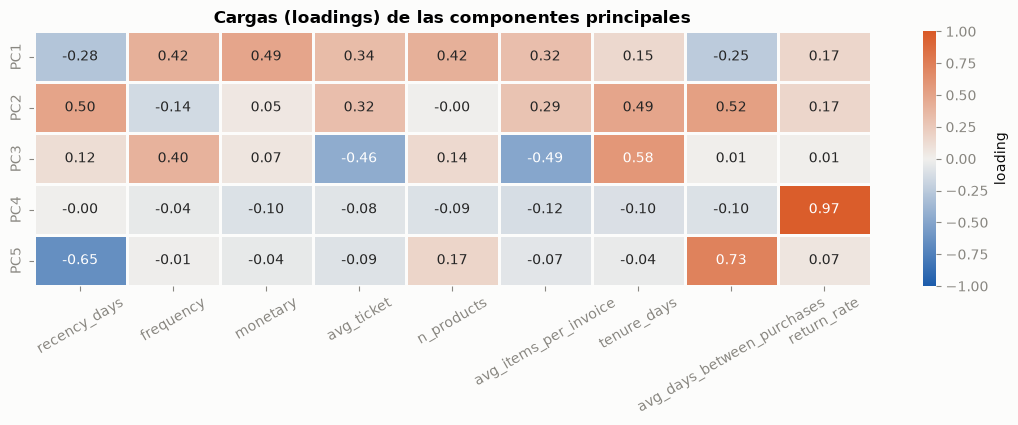

In [24]:
load = pd.DataFrame(pca.components_, columns=FEATURES, index=[f"PC{i+1}" for i in range(N_PC)])
fig, ax = plt.subplots(figsize=(11, 0.55 * N_PC + 1.6))
sns.heatmap(load, annot=True, fmt=".2f", cmap=DIV_CMAP, center=0, vmin=-1, vmax=1, ax=ax,
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "loading"})
ax.set_title("Cargas (loadings) de las componentes principales"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig(fig, "e2_pca_loadings"); plt.show()

**Interpretación de las componentes** (ver cargas): **PC1 = valor/actividad** del cliente (gasto 0,49, frecuencia 0,42, n.º de productos 0,42; recencia −0,28). **PC2 = eje temporal / inactividad** (recencia 0,50, antigüedad 0,49, días entre compras 0,52). **PC3 = tamaño de pedido** frente a antigüedad (ticket medio −0,46, unidades por factura −0,49, antigüedad 0,58). **PC4 = devoluciones** (`return_rate` 0,97). **PC5 = recencia frente a ritmo de recompra**. Las correlaciones vistas en la sección 3.2 son las que permiten esta compresión.

### 6.2 K-Means y GMM sobre PCA — misma búsqueda, misma regla

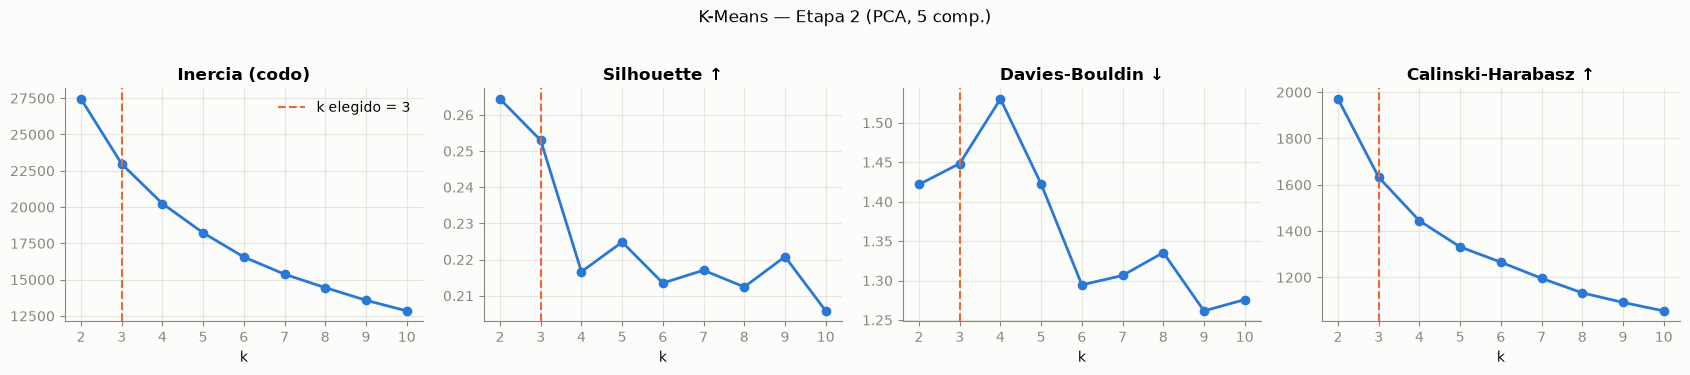

,k,inertia,min_cluster_frac,silhouette,davies_bouldin,calinski_harabasz
0,2,27446.587,0.484,0.264,1.422,1970.644
1,3,22966.466,0.261,0.253,1.448,1632.085
2,4,20236.960,0.209,0.217,1.530,1444.164
3,5,18222.914,0.124,0.225,1.422,1331.350
4,6,16560.236,0.122,0.214,1.294,1265.345
5,7,15373.140,0.092,0.217,1.306,1195.600
6,8,14448.978,0.084,0.212,1.335,1132.679
7,9,13580.256,0.071,0.221,1.262,1091.498
8,10,12847.450,0.063,0.206,1.276,1054.849


K-Means seleccionado: k=3 | búsqueda: 4.3s (Etapa 1: 4.1s)


In [25]:
t0 = time.perf_counter(); km2_res = search_kmeans(Z_train); t_km2 = time.perf_counter() - t0
best_km2 = select_best(km2_res); K_KM2 = int(best_km2.k)
plot_kmeans_search(km2_res, K_KM2, f"K-Means — Etapa 2 (PCA, {N_PC} comp.)", "e2_kmeans_search")
display(km2_res.round(3))
print(f"K-Means seleccionado: k={K_KM2} | búsqueda: {t_km2:.1f}s (Etapa 1: {t_km1:.1f}s)")

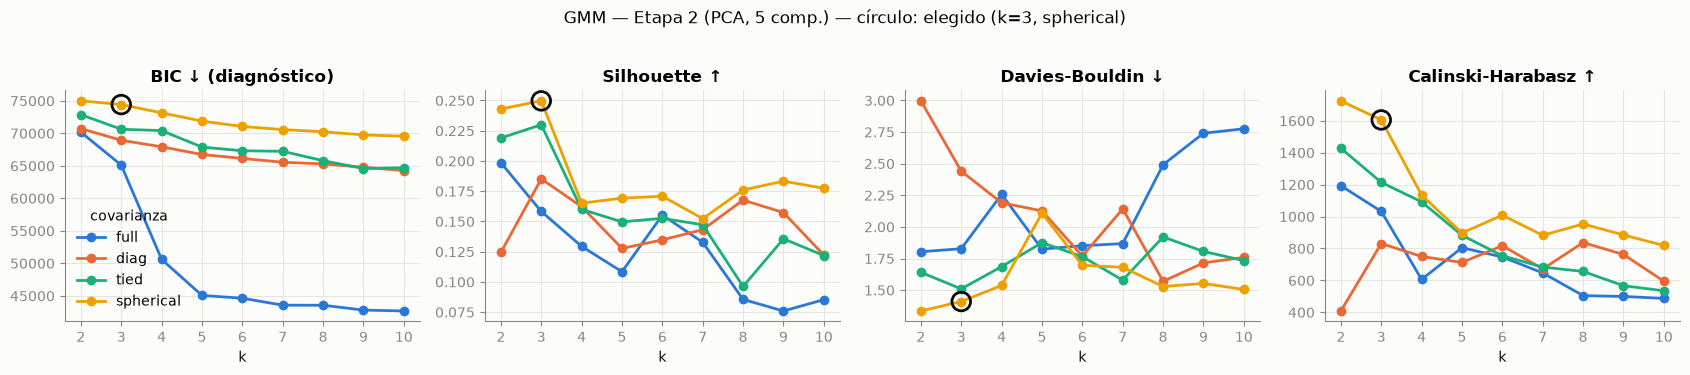

,k,covariance_type,bic,aic,n_used_clusters,min_cluster_frac,silhouette,davies_bouldin,calinski_harabasz
28,3,spherical,74418.914,74289.953,3,0.223,0.250,1.410,1604.922
27,2,spherical,74993.678,74909.853,2,0.326,0.243,1.335,1724.319
19,3,tied,70627.193,70420.855,3,0.228,0.230,1.510,1214.035
18,2,tied,72865.261,72697.611,2,0.462,0.219,1.641,1427.277
0,2,full,70174.918,69910.548,2,0.478,0.199,1.804,1192.918
10,3,diag,68931.913,68725.575,3,0.263,0.185,2.441,830.984
34,9,spherical,69753.328,69353.548,9,0.053,0.183,1.553,884.763
35,10,spherical,69554.332,69109.416,10,0.031,0.177,1.505,818.781
33,8,spherical,70235.694,69881.051,8,0.066,0.176,1.529,953.398
31,6,spherical,71047.630,70783.260,6,0.110,0.171,1.697,1008.330


GMM seleccionado: k=3, covariance_type='spherical' | búsqueda: 24.6s (Etapa 1: 26.8s)


In [26]:
t0 = time.perf_counter(); gm2_res = search_gmm(Z_train); t_gm2 = time.perf_counter() - t0
best_gm2 = select_best(gm2_res); K_GM2, COV_GM2 = int(best_gm2.k), best_gm2.covariance_type
plot_gmm_search(gm2_res, K_GM2, COV_GM2, f"GMM — Etapa 2 (PCA, {N_PC} comp.)", "e2_gmm_search")
display(gm2_res.sort_values("silhouette", ascending=False).head(10).round(3))
print(f"GMM seleccionado: k={K_GM2}, covariance_type='{COV_GM2}' | búsqueda: {t_gm2:.1f}s (Etapa 1: {t_gm1:.1f}s)")

### 6.3 Evaluación — en el espacio PCA **y** en el espacio original
Silhouette, DB y CH dependen de las distancias del espacio donde se calculan: un mismo agrupamiento puntúa distinto en 5 que en 9 dimensiones. Para que la comparación con la Etapa 1 sea justa, las etiquetas de la Etapa 2 se evalúan también sobre `X_train`/`X_test` originales escalados.

In [27]:
kmeans2 = make_kmeans(K_KM2).fit(Z_train)
gmm2 = make_gmm(K_GM2, COV_GM2).fit(Z_train)
orig = {"original": (X_train, X_test)}
e2 = pd.concat([tag(evaluate_model(kmeans2, Z_train, Z_test, orig), f"K-Means (k={K_KM2})", 2, "PCA"),
                tag(evaluate_model(gmm2, Z_train, Z_test, orig), f"GMM (k={K_GM2}, {COV_GM2})", 2, "PCA")])
e2["espacio_métrica"] = e2["espacio_métrica"].replace({"propio": "PCA"})
display(e2.set_index(["modelo", "espacio_métrica", "conjunto"])[["silhouette", "davies_bouldin", "calinski_harabasz"]].round(3))

silhouette  davies_bouldin  calinski_harabasz
modelo               espacio_métrica conjunto                                               
K-Means (k=3)        PCA             train          0.253           1.448           1632.085
                                     test           0.251           1.438            406.427
                     original        train          0.232           1.550           1448.191
                                     test           0.231           1.533            363.613
GMM (k=3, spherical) PCA             train          0.250           1.410           1604.922
                                     test           0.246           1.406            400.370
                     original        train          0.228           1.511           1424.934
                                     test           0.225           1.501            358.291

,n_clientes,%,recency_days,frequency,monetary,avg_ticket,n_products,avg_items_per_invoice,tenure_days,avg_days_between_purchases,return_rate
cluster,,,,,,,,,,,
0,1920,41.1,43.0,8.0,2765.5,358.2,117.0,210.7,652.0,67.5,0.1
1,1219,26.1,46.0,2.0,566.1,255.4,31.0,153.0,147.0,53.0,0.0
2,1527,32.7,409.0,1.0,310.1,186.7,19.0,100.0,551.0,342.0,0.0


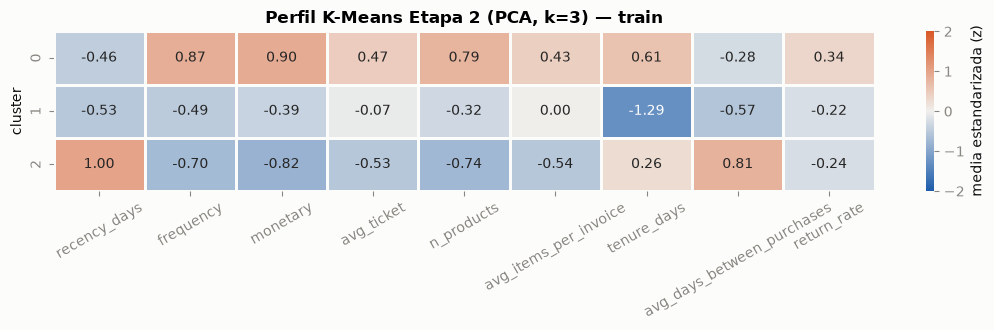

In [28]:
# Perfil en variables originales (las componentes PCA no son interpretables directamente por negocio)
lab_km2 = show_profile(canon(kmeans2.predict(Z_train)), train_df, f"Perfil K-Means Etapa 2 (PCA, k={K_KM2}) — train", "e2_kmeans_profile")

### 6.4 Estabilidad: ¿cambian los segmentos al reducir dimensión?
ARI entre las cuatro particiones de train (1 = idénticas, 0 = coincidencia al azar). No es validación externa: solo compara particiones entre sí.

,n_clientes,%,recency_days,frequency,monetary,avg_ticket,n_products,avg_items_per_invoice,tenure_days,avg_days_between_purchases,return_rate
cluster,,,,,,,,,,,
0,2024,43.4,43.0,7.0,2609.6,352.5,114.0,208.5,645.0,68.4,0.1
1,1040,22.3,44.0,2.0,544.2,256.9,31.0,154.5,115.0,50.0,0.0
2,1602,34.3,407.0,1.0,309.6,186.5,18.0,100.0,541.0,322.5,0.0


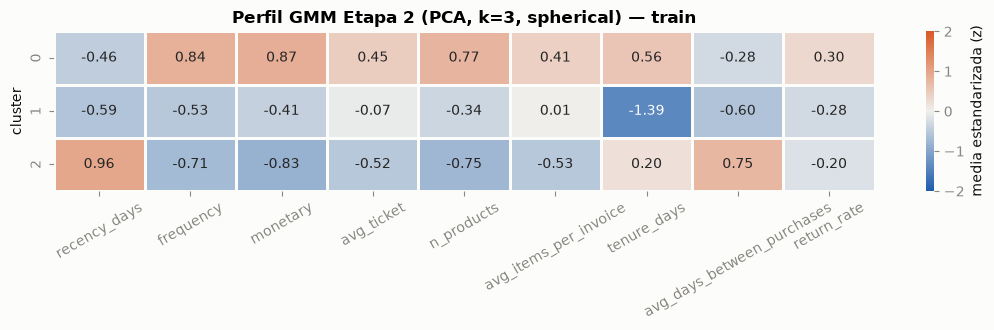

In [29]:
lab_gm2 = show_profile(canon(gmm2.predict(Z_train)), train_df, f"Perfil GMM Etapa 2 (PCA, k={K_GM2}, {COV_GM2}) — train", "e2_gmm_profile")

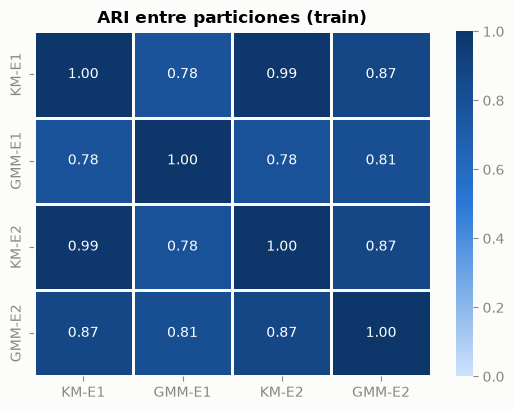

In [30]:
parts = {"KM-E1": lab_km1, "GMM-E1": lab_gm1, "KM-E2": lab_km2, "GMM-E2": lab_gm2}
ari = pd.DataFrame([[adjusted_rand_score(a, b) for b in parts.values()] for a in parts.values()],
                   index=parts.keys(), columns=parts.keys())
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(ari, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, linewidths=2, linecolor="#fcfcfb")
ax.set_title("ARI entre particiones (train)"); plt.tight_layout(); save_fig(fig, "e2_ari_stability"); plt.show()

## 7. Comparación adicional opcional — UMAP
UMAP es una reducción **no lineal** que preserva vecindarios locales. Se ajusta solo con train (`fit`) y se proyecta test con `transform`. Se usan 5 componentes (igual que PCA, para comparar a igual dimensión), `n_neighbors=30` y `min_dist=0.0`, que son la configuración recomendada para clustering.

⚠️ UMAP tiende a "compactar" grupos, por lo que las métricas calculadas *en* el espacio UMAP salen infladas; la comparación justa es en el espacio original.

In [31]:
import umap
t0 = time.perf_counter()
reducer = umap.UMAP(n_components=N_PC, n_neighbors=30, min_dist=0.0, random_state=SEED).fit(X_train)
U_train = reducer.embedding_.astype(np.float64)
U_test = reducer.transform(X_test).astype(np.float64)
print(f"UMAP ajustado en {time.perf_counter()-t0:.1f}s")

km3_res, gm3_res = search_kmeans(U_train), search_gmm(U_train)
best_km3, best_gm3 = select_best(km3_res), select_best(gm3_res)
K_KM3, K_GM3, COV_GM3 = int(best_km3.k), int(best_gm3.k), best_gm3.covariance_type
kmeans3 = make_kmeans(K_KM3).fit(U_train)
gmm3 = make_gmm(K_GM3, COV_GM3).fit(U_train)
e3 = pd.concat([tag(evaluate_model(kmeans3, U_train, U_test, orig), f"K-Means (k={K_KM3})", "2-UMAP", "UMAP"),
                tag(evaluate_model(gmm3, U_train, U_test, orig), f"GMM (k={K_GM3}, {COV_GM3})", "2-UMAP", "UMAP")])
e3["espacio_métrica"] = e3["espacio_métrica"].replace({"propio": "UMAP"})
display(e3.set_index(["modelo", "espacio_métrica", "conjunto"])[["silhouette", "davies_bouldin", "calinski_harabasz"]].round(3))
lab_km3, lab_gm3 = canon(kmeans3.predict(U_train)), canon(gmm3.predict(U_train))

/home/nicolas/Documentos/2026/Universidad/MachineLearning/online_retail/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP ajustado en 26.2s


silhouette  davies_bouldin  calinski_harabasz
modelo               espacio_métrica conjunto                                               
K-Means (k=5)        UMAP            train          0.527           0.673          17212.344
                                     test           0.513           0.687           4373.495
                     original        train          0.181           1.765            958.561
                                     test           0.178           1.694            249.864
GMM (k=5, spherical) UMAP            train          0.527           0.671          17179.924
                                     test           0.511           0.684           4351.301
                     original        train          0.180           1.768            957.786
                                     test           0.176           1.698            249.100

## 8. Visualización con t-SNE (solo visualización)
t-SNE **no** se usa para entrenar ni para elegir nada: no tiene `transform` para datos nuevos y distorsiona distancias globales. Se proyecta `X_train` a 2D una sola vez y se colorea con las etiquetas de cada modelo para ver si los segmentos ocupan regiones coherentes.

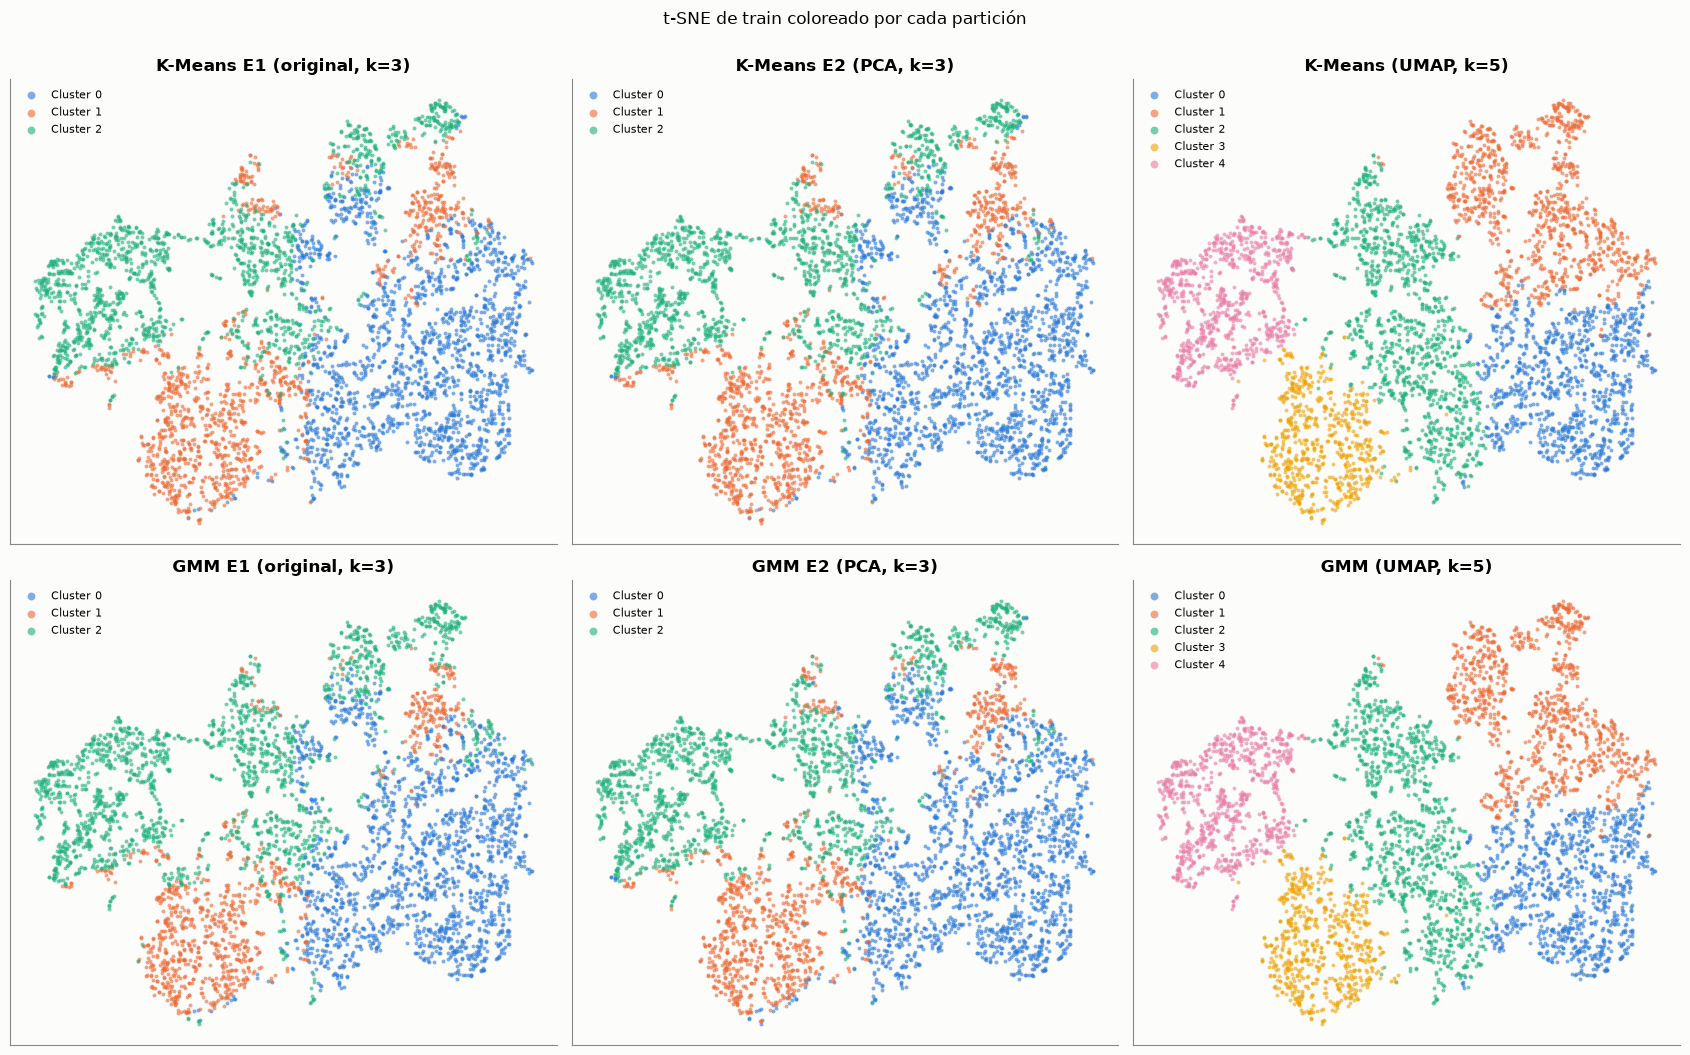

In [32]:
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(X_train)
fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
panels = [(lab_km1, f"K-Means E1 (original, k={K_KM1})"), (lab_km2, f"K-Means E2 (PCA, k={K_KM2})"), (lab_km3, f"K-Means (UMAP, k={K_KM3})"),
          (lab_gm1, f"GMM E1 (original, k={K_GM1})"), (lab_gm2, f"GMM E2 (PCA, k={K_GM2})"), (lab_gm3, f"GMM (UMAP, k={K_GM3})")]
for ax, (lab, title) in zip(axes.ravel(), panels):
    scatter_clusters(ax, emb, lab, title)
fig.suptitle("t-SNE de train coloreado por cada partición", y=1.0)
plt.tight_layout(); save_fig(fig, "tsne_clusters"); plt.show()

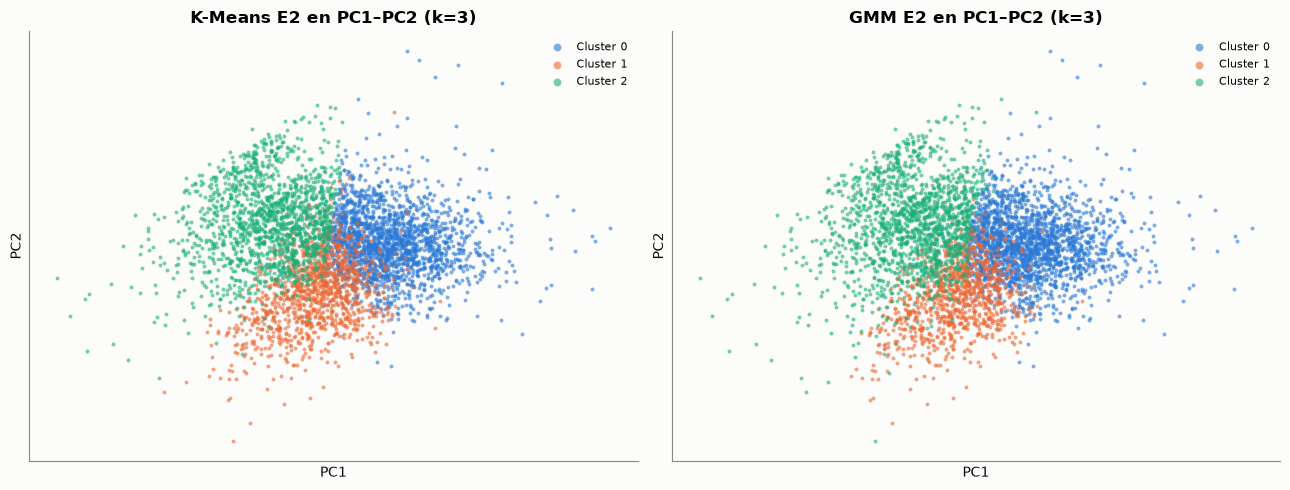

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scatter_clusters(axes[0], Z_train[:, :2], lab_km2, f"K-Means E2 en PC1–PC2 (k={K_KM2})")
scatter_clusters(axes[1], Z_train[:, :2], lab_gm2, f"GMM E2 en PC1–PC2 (k={K_GM2})")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); save_fig(fig, "e2_pca_scatter"); plt.show()

## 9. Comparación final
Tabla maestra con todas las combinaciones. La columna clave para comparar etapas es **test evaluado en el espacio original** (mismo espacio de distancias para todos).

In [34]:
allres = pd.concat([e1.assign(espacio_métrica=e1["espacio_métrica"].replace({"propio": "original"})), e2, e3])
allres["familia"] = np.where(allres.modelo.str.startswith("K-Means"), "K-Means", "GMM")
master = (allres.pivot_table(index=["etapa", "espacio_modelo", "modelo"], columns=["espacio_métrica", "conjunto"],
                             values=["silhouette", "davies_bouldin", "calinski_harabasz"], aggfunc="first")
          .round(3))
display(master)
allres.to_csv(ROOT / "reports" / "metricas_comparacion.csv", index=False)

calinski_harabasz                                                   davies_bouldin                                      silhouette                       \
espacio_métrica                                          PCA                UMAP            original                      PCA          UMAP        original               PCA          UMAP          
conjunto                                                test     train      test      train     test     train           test  train   test  train     test  train       test  train   test  train   
etapa  espacio_modelo modelo                                                                                                                                                                         
1      original       GMM (k=3, spherical)               NaN       NaN       NaN        NaN  339.312  1327.393            NaN    NaN    NaN    NaN    1.509  1.555        NaN    NaN    NaN    NaN   
                      K-Means (k=3)                      NaN       NaN       NaN        NaN  364.164  1448.366            NaN    NaN    NaN    NaN    1.530  1.550        NaN    NaN    NaN    NaN   
2      PCA            GMM (k=3, spherical)           400.370  1604.922       NaN        NaN  358.291  1424.934          1.406  1.410    NaN    NaN    1.501  1.511      0.246  0.250    NaN    NaN   
                      K-Means (k=3)                  406.427  1632.085       NaN        NaN  363.613  1448.191          1.438  1.448    NaN    NaN    1.533  1.550      0.251  0.253    NaN    NaN   
2-UMAP UMAP           GMM (k=5, spherical)               NaN       NaN  4351.301  17179.924  249.100   957.786            NaN    NaN  0.684  0.671    1.698  1.768        NaN    NaN  0.511  0.527   
                      K-Means (k=5)                      NaN       NaN  4373.495  17212.344  249.864   958.561            NaN    NaN  0.687  0.673    1.694  1.765        NaN    NaN  0.513  0.527   

                                                            
espacio_métrica                            original         
conjunto                                       test  train  
etapa  espacio_modelo modelo                                
1      original       GMM (k=3, spherical)    0.215  0.213  
                      K-Means (k=3)           0.231  0.232  
2      PCA            GMM (k=3, spherical)    0.225  0.228  
                      K-Means (k=3)           0.231  0.232  
2-UMAP UMAP           GMM (k=5, spherical)    0.176  0.180  
                      K-Means (k=5)           0.178  0.181

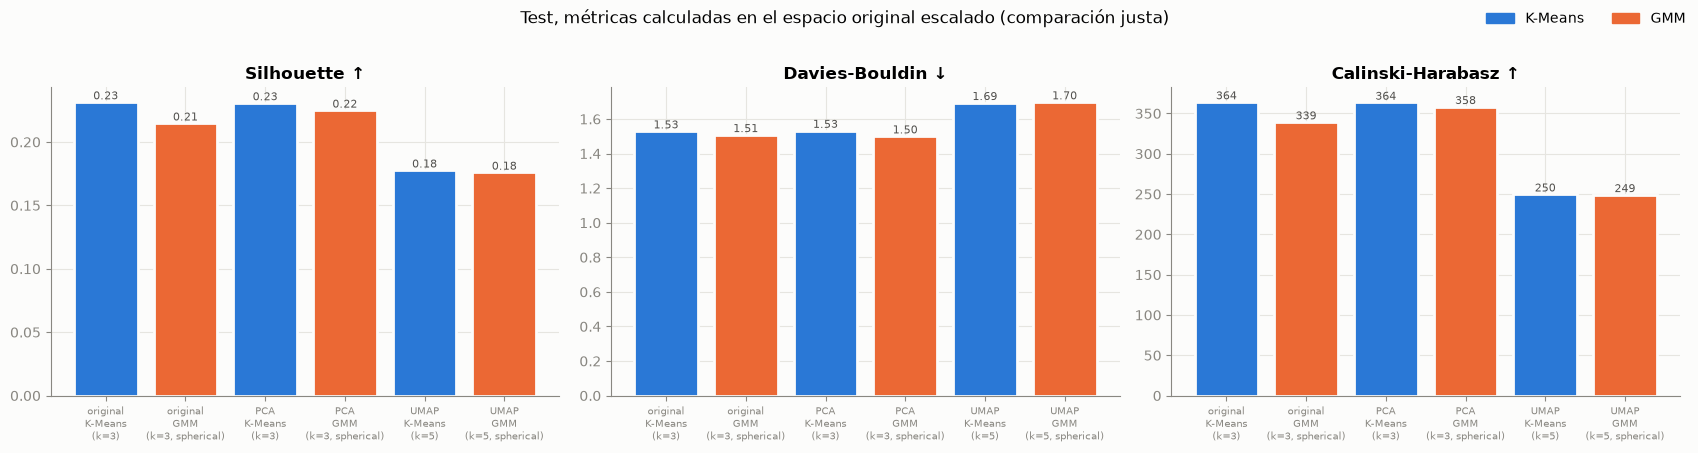

In [35]:
fair = allres[(allres.espacio_métrica == "original") & (allres.conjunto == "test")].copy()
fair["config"] = fair.espacio_modelo + "\n" + fair.modelo.str.replace(r" \(", "\n(", regex=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (col, lab) in zip(axes, [("silhouette", "Silhouette ↑"), ("davies_bouldin", "Davies-Bouldin ↓"),
                                 ("calinski_harabasz", "Calinski-Harabasz ↑")]):
    colors = [PALETTE[0] if f == "K-Means" else PALETTE[1] for f in fair.familia]
    bars = ax.bar(range(len(fair)), fair[col], color=colors, edgecolor="#fcfcfb", linewidth=2)
    ax.bar_label(bars, fmt="%.2f" if col != "calinski_harabasz" else "%.0f", fontsize=8, color="#52514e")
    ax.set_xticks(range(len(fair))); ax.set_xticklabels(fair.config, fontsize=7.5); ax.set_title(lab)
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[0]), plt.Rectangle((0, 0), 1, 1, color=PALETTE[1])]
fig.legend(handles, ["K-Means", "GMM"], loc="upper right", ncol=2)
fig.suptitle("Test, métricas calculadas en el espacio original escalado (comparación justa)", y=1.02)
plt.tight_layout(); save_fig(fig, "final_comparacion"); plt.show()

In [36]:
timing = pd.DataFrame({"búsqueda K-Means (s)": [t_km1, t_km2], "búsqueda GMM (s)": [t_gm1, t_gm2]},
                      index=["Etapa 1 (9D)", f"Etapa 2 (PCA {N_PC}D)"]).round(2)
display(timing)

,búsqueda K-Means (s),búsqueda GMM (s)
Etapa 1 (9D),4.07,26.81
Etapa 2 (PCA 5D),4.28,24.62


### 9.1 Tabla comparativa obligatoria
Tiempo = mediana de 5 entrenamientos del modelo final (solo `fit`, sin la búsqueda de hiperparámetros). Las métricas de las filas PCA se calculan en el espacio PCA, que es el espacio del modelo. Los valores de esas mismas etiquetas medidas en el espacio original están en la tabla maestra. % ruido = 0 porque ni K-Means ni GMM tienen ruido: todos los puntos se asignan a algún cluster. ARI vs. original = concordancia entre las etiquetas de train del modelo en PCA y las del mismo modelo en el espacio original.

In [37]:
def fit_time(make, X, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); make().fit(X); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

def fmt(tr, te, d=3):
    return f"{tr:.{d}f} / {te:.{d}f}"

specs = [
    ("Modelo A: K-Means", f"Original ({X_train.shape[1]} variables)", f"n_clusters={K_KM1}, n_init=10, init=k-means++", kmeans1, X_train, X_test, lambda: make_kmeans(K_KM1), None),
    ("Modelo A: K-Means", f"PCA ({N_PC} comp.)", f"n_clusters={K_KM2}, n_init=10, init=k-means++", kmeans2, Z_train, Z_test, lambda: make_kmeans(K_KM2), lab_km1),
    ("Modelo B: GMM", f"Original ({X_train.shape[1]} variables)", f"n_components={K_GM1}, covariance_type='{COV_GM1}', n_init=3", gmm1, X_train, X_test, lambda: make_gmm(K_GM1, COV_GM1), None),
    ("Modelo B: GMM", f"PCA ({N_PC} comp.)", f"n_components={K_GM2}, covariance_type='{COV_GM2}', n_init=3", gmm2, Z_train, Z_test, lambda: make_gmm(K_GM2, COV_GM2), lab_gm1),
]
rows = []
for modelo, espacio, hp, m, A, B, mk, ref in specs:
    la, lb = m.predict(A), m.predict(B)
    ma, mb = internal_metrics(A, la), internal_metrics(B, lb)
    rows.append({
        "Modelo": modelo, "Espacio": espacio, "Hiperparámetros": hp, "N.° grupos": len(np.unique(la)),
        "Silhouette ↑ (train / test)": fmt(ma["silhouette"], mb["silhouette"]),
        "Davies-Bouldin ↓ (train / test)": fmt(ma["davies_bouldin"], mb["davies_bouldin"]),
        "Calinski-Harabasz ↑ (train / test)": fmt(ma["calinski_harabasz"], mb["calinski_harabasz"], 1),
        "% ruido": "0 %",
        "Tiempo (s)": round(fit_time(mk, A), 3),
        "ARI vs. original": "—" if ref is None else round(adjusted_rand_score(ref, la), 3),
    })
tabla_obligatoria = pd.DataFrame(rows)
tabla_obligatoria.to_csv(ROOT / "reports" / "tabla_comparativa_obligatoria.csv", index=False)
display(tabla_obligatoria)

,Modelo,Espacio,Hiperparámetros,N.° grupos,Silhouette ↑ (train / test),Davies-Bouldin ↓ (train / test),Calinski-Harabasz ↑ (train / test),% ruido,Tiempo (s),ARI vs. original
0,Modelo A: K-Means,Original (9 variables),"n_clusters=3, n_init=10, init=k-means++",3,0.232 / 0.231,1.550 / 1.530,1448.4 / 364.2,0 %,0.065,—
1,Modelo A: K-Means,PCA (5 comp.),"n_clusters=3, n_init=10, init=k-means++",3,0.253 / 0.251,1.448 / 1.438,1632.1 / 406.4,0 %,0.039,0.989
2,Modelo B: GMM,Original (9 variables),"n_components=3, covariance_type='spherical', n...",3,0.213 / 0.215,1.555 / 1.509,1327.4 / 339.3,0 %,0.113,—
3,Modelo B: GMM,PCA (5 comp.),"n_components=3, covariance_type='spherical', n...",3,0.250 / 0.246,1.410 / 1.406,1604.9 / 400.4,0 %,0.031,0.813


## 10. Experimentos complementarios (preguntas de análisis)
Estos experimentos aportan las cifras con que se responden las preguntas del informe sobre escalado, atípicos, estabilidad y costo computacional. Ninguno se usa para elegir hiperparámetros: los modelos y los valores de k son los ya seleccionados.

### 10.1 Efecto del escalado y de los atípicos
Se entrena K-Means y GMM con el **mismo k** y el **mismo tipo de covarianza** que los modelos elegidos, en cuatro variantes de preprocesamiento. Para poder comparar, las métricas se calculan en el espacio escalado común (`X_train`). Se reporta también la variable que domina la varianza total, los tamaños de los clusters y el ARI frente a la partición elegida.

In [38]:
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def build_variant(use_log, use_scale):
    A = (log_transform(train_df, LOG_COLS) if use_log else train_df)[FEATURES].to_numpy(dtype=float)
    return StandardScaler().fit_transform(A) if use_scale else A

variants = {"Sin log, sin escalar": (False, False), "Sin log, con escalado": (False, True),
            "Con log, sin escalar": (True, False), "Con log + escalado (elegido)": (True, True)}
ref_lab = {"K-Means": lab_km1, "GMM": lab_gm1}
makers = {"K-Means": lambda: make_kmeans(K_KM1), "GMM": lambda: make_gmm(K_GM1, COV_GM1)}
rows, variant_labels = [], {}
for vname, (ul, us) in variants.items():
    A = build_variant(ul, us)
    share = A.var(0) / A.var(0).sum()
    for mname, mk in makers.items():
        lab = canon(mk().fit(A).predict(A))
        variant_labels[(vname, mname)] = lab
        counts = np.bincount(lab, minlength=K_KM1)
        small = int(counts.argmin())
        mc = internal_metrics(X_train, lab)
        rows.append({"variante": vname, "modelo": mname,
                     "variable dominante": f"{FEATURES[int(share.argmax())]} ({share.max():.0%} de la varianza)",
                     "tamaños (%)": " / ".join(f"{x:.1f}" for x in sorted(counts / len(lab) * 100, reverse=True)),
                     "cluster más pequeño: n": int(counts.min()),
                     "cluster más pequeño: gasto mediano (£)": round(float(np.median(train_df.monetary.values[lab == small])), 0),
                     "Silhouette (espacio propio)": round(internal_metrics(A, lab)["silhouette"], 3),
                     "Silhouette (común)": round(mc["silhouette"], 3), "DB (común)": round(mc["davies_bouldin"], 3),
                     "CH (común)": round(mc["calinski_harabasz"], 1),
                     "ARI vs elegido": round(adjusted_rand_score(ref_lab[mname], lab), 3)})
scaling_tbl = pd.DataFrame(rows)
scaling_tbl.to_csv(ROOT / "reports" / "exp_escalado_atipicos.csv", index=False)
display(scaling_tbl)


,variante,modelo,variable dominante,tamaños (%),cluster más pequeño: n,cluster más pequeño: gasto mediano (£),Silhouette (espacio propio),Silhouette (común),DB (común),CH (común),ARI vs elegido
0,"Sin log, sin escalar",K-Means,monetary (98% de la varianza),99.7 / 0.3 / 0.0,2,550806.0,0.974,0.443,1.115,41.7,-0.001
1,"Sin log, sin escalar",GMM,monetary (98% de la varianza),66.3 / 26.9 / 6.8,317,11920.0,0.520,0.147,1.801,915.9,0.275
2,"Sin log, con escalado",K-Means,recency_days (11% de la varianza),69.7 / 30.0 / 0.3,13,168504.0,0.262,0.187,1.407,589.1,0.312
3,"Sin log, con escalado",GMM,recency_days (11% de la varianza),86.0 / 12.3 / 1.7,79,30375.0,0.141,0.108,1.540,347.6,0.165
4,"Con log, sin escalar",K-Means,tenure_days (54% de la varianza),41.0 / 30.6 / 28.4,1325,509.0,0.551,0.198,1.684,1042.7,0.466
5,"Con log, sin escalar",GMM,tenure_days (54% de la varianza),35.9 / 33.3 / 30.8,1439,2948.0,0.527,0.175,1.793,998.0,0.375
6,Con log + escalado (elegido),K-Means,recency_days (11% de la varianza),41.2 / 32.6 / 26.2,1223,564.0,0.232,0.232,1.550,1448.4,1.000
7,Con log + escalado (elegido),GMM,recency_days (11% de la varianza),40.0 / 39.6 / 20.4,952,564.0,0.213,0.213,1.555,1327.4,1.000


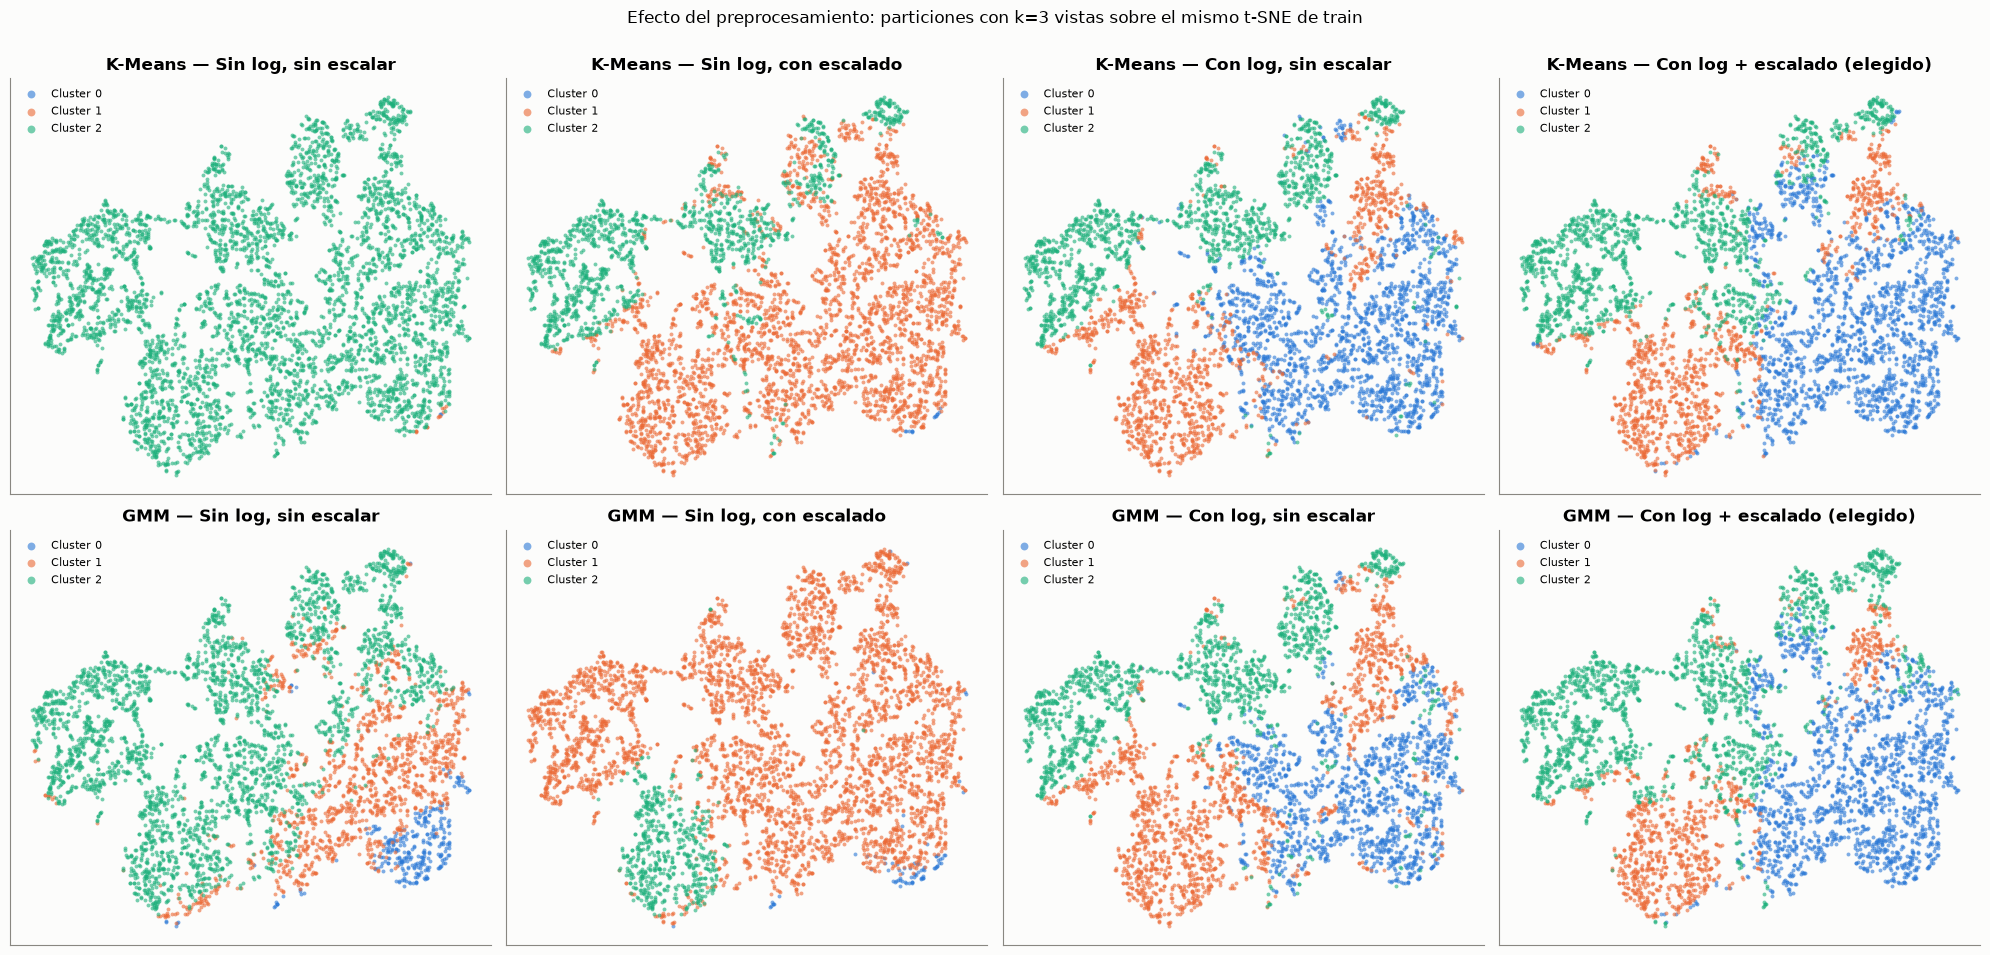

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for j, vname in enumerate(variants):
    for i, mname in enumerate(makers):
        scatter_clusters(axes[i, j], emb, variant_labels[(vname, mname)], f"{mname} — {vname}")
fig.suptitle("Efecto del preprocesamiento: particiones con k=3 vistas sobre el mismo t-SNE de train", y=1.0)
plt.tight_layout(); save_fig(fig, "exp_escalado_tsne"); plt.show()


### 10.2 ¿Dónde quedan los clientes atípicos en los modelos elegidos?

In [40]:
top1 = (train_df.monetary >= train_df.monetary.quantile(0.99)).values
print(f"Clientes del 1 % superior en gasto (train): {top1.sum()}")
print("  Cluster K-Means E1:", pd.Series(lab_km1[top1]).value_counts().sort_index().to_dict())
print("  Cluster GMM E1:    ", pd.Series(lab_gm1[top1]).value_counts().sort_index().to_dict())

dist = kmeans1.transform(X_train).min(1)
far = dist >= np.quantile(dist, 0.99)
ll = gmm1.score_samples(X_train)
low = ll <= np.quantile(ll, 0.01)
cmp = pd.DataFrame({
    "todos (mediana)": train_df[FEATURES].median(),
    "1 % más lejano al centroide (K-Means)": train_df[FEATURES][far].median(),
    "1 % menos verosímil (GMM)": train_df[FEATURES][low].median()}).round(1)
display(cmp)
print(f"Coincidencia entre ambos grupos de atípicos: {(far & low).sum()} de {far.sum()} clientes")
print(f"Distancia al centroide: mediana={np.median(dist):.2f}, p99={np.quantile(dist,.99):.2f}, máx={dist.max():.2f}")


Clientes del 1 % superior en gasto (train): 47
  Cluster K-Means E1: {0: 46, 1: 1}
  Cluster GMM E1:     {0: 46, 2: 1}


,todos (mediana),1 % más lejano al centroide (K-Means),1 % menos verosímil (GMM)
recency_days,92.0,154.0,59.0
frequency,3.0,2.0,3.0
monetary,848.0,4255.4,8438.3
avg_ticket,277.4,1368.1,2104.7
n_products,45.0,29.0,57.0
avg_items_per_invoice,155.0,886.5,1140.8
tenure_days,530.0,550.0,562.0
avg_days_between_purchases,88.8,23.0,12.4
return_rate,0.0,0.1,0.1


Coincidencia entre ambos grupos de atípicos: 40 de 47 clientes
Distancia al centroide: mediana=2.03, p99=5.39, máx=10.99


### 10.3 Estabilidad frente a semillas y submuestras
- **Semillas:** se reentrena cada modelo con 10 semillas distintas, con el `n_init` elegido y con `n_init=1` (una sola inicialización), y se compara con la partición de referencia (ARI).
- **Submuestras:** se entrena con 20 submuestras aleatorias del 80 % de train, se predice sobre todo train y se compara con la partición de referencia.

In [41]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
def km_(k, s, n_init=10): return KMeans(n_clusters=k, n_init=n_init, random_state=s)
def gm_(k, cov, s, n_init=3): return GaussianMixture(n_components=k, covariance_type=cov, n_init=n_init, random_state=s)

configs = [("K-Means", "Original", X_train, lab_km1, lambda s, ni=10: km_(K_KM1, s, ni)),
           ("K-Means", "PCA", Z_train, lab_km2, lambda s, ni=10: km_(K_KM2, s, ni)),
           ("GMM", "Original", X_train, lab_gm1, lambda s, ni=3: gm_(K_GM1, COV_GM1, s, ni)),
           ("GMM", "PCA", Z_train, lab_gm2, lambda s, ni=3: gm_(K_GM2, COV_GM2, s, ni))]
rng = np.random.default_rng(SEED)
sub_idx = [rng.choice(len(X_train), int(0.8 * len(X_train)), replace=False) for _ in range(20)]
stab_rows, sub_long = [], []
for mname, space, A, ref, mk in configs:
    seeds_def = [adjusted_rand_score(ref, mk(s).fit(A).predict(A)) for s in range(10)]
    seeds_one = [adjusted_rand_score(ref, mk(s, 1).fit(A).predict(A)) for s in range(10)]
    subs = [adjusted_rand_score(ref, mk(SEED).fit(A[ix]).predict(A)) for ix in sub_idx]
    sub_long += [{"config": f"{mname}\n{space}", "ARI": v} for v in subs]
    for prueba, vals in [("10 semillas (n_init elegido)", seeds_def), ("10 semillas (n_init=1)", seeds_one),
                         ("20 submuestras 80 %", subs)]:
        stab_rows.append({"modelo": mname, "espacio": space, "prueba": prueba,
                          "ARI medio": np.mean(vals), "ARI desv.": np.std(vals), "ARI mín.": np.min(vals)})
stab_tbl = pd.DataFrame(stab_rows).round(3)
stab_tbl.to_csv(ROOT / "reports" / "exp_estabilidad.csv", index=False)
display(stab_tbl.pivot_table(index=["modelo", "espacio"], columns="prueba", values=["ARI medio", "ARI mín."]))


ARI medio                                                                ARI mín.                                           
prueba           10 semillas (n_init elegido) 10 semillas (n_init=1) 20 submuestras 80 % 10 semillas (n_init elegido) 10 semillas (n_init=1) 20 submuestras 80 %
modelo  espacio                                                                                                                                                 
GMM     Original                        0.949                  0.949               0.871                        0.504                  0.504               0.291
        PCA                             0.996                  0.993               0.834                        0.994                  0.990               0.149
K-Means Original                        0.998                  0.942               0.977                        0.995                  0.447               0.919
        PCA                             0.997                  0.997               0.978                        0.994                  0.995               0.950

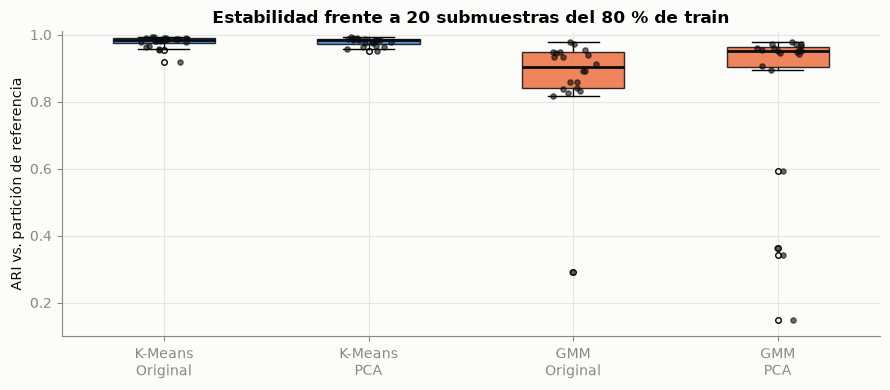

In [42]:
sub_df = pd.DataFrame(sub_long)
order = sub_df.config.unique()
fig, ax = plt.subplots(figsize=(9, 4))
data = [sub_df[sub_df.config == c].ARI.values for c in order]
bp = ax.boxplot(data, tick_labels=order, patch_artist=True, widths=0.5,
                medianprops={"color": TEXT_COLOR, "linewidth": 2}, flierprops={"markersize": 4})
for patch, c in zip(bp["boxes"], order):
    patch.set_facecolor(PALETTE[0] if c.startswith("K-Means") else PALETTE[1]); patch.set_alpha(0.8)
for i, d in enumerate(data, 1):
    ax.scatter(np.full(len(d), i) + np.random.default_rng(i).uniform(-.12, .12, len(d)), d, s=14, color=TEXT_COLOR, alpha=.6, zorder=3)
ax.set_ylabel("ARI vs. partición de referencia"); ax.set_ylim(min(0.5, sub_df.ARI.min() - .05), 1.01)
ax.set_title("Estabilidad frente a 20 submuestras del 80 % de train")
plt.tight_layout(); save_fig(fig, "exp_estabilidad"); plt.show()


### 10.4 Costo computacional y escalabilidad
Se miden los tiempos de entrenamiento (`fit`), de predicción (`predict` sobre test) y del cálculo de Silhouette (mediana de 5 repeticiones). Para estimar el efecto de **100 veces más observaciones**, se replica train 4 y 10 veces añadiendo un pequeño ruido gaussiano (σ = 0,05), se miden los tiempos y se extrapola con el exponente observado.

In [43]:
from sklearn.metrics import silhouette_score
def med_time(f, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

rng = np.random.default_rng(SEED)
X10 = np.repeat(X_train, 10, axis=0) + rng.normal(0, 0.05, (10 * len(X_train), X_train.shape[1]))
X4 = X10[rng.choice(len(X10), 4 * len(X_train), replace=False)]
Z10, Z4 = pca.transform(X10), pca.transform(X4)

cost_rows = []
for mname, space, A, A4, A10, B, mk in [
        ("K-Means", "Original", X_train, X4, X10, X_test, lambda: make_kmeans(K_KM1)),
        ("K-Means", "PCA", Z_train, Z4, Z10, Z_test, lambda: make_kmeans(K_KM2)),
        ("GMM", "Original", X_train, X4, X10, X_test, lambda: make_gmm(K_GM1, COV_GM1)),
        ("GMM", "PCA", Z_train, Z4, Z10, Z_test, lambda: make_gmm(K_GM2, COV_GM2))]:
    m = mk().fit(A)
    t_fit1, t_fit10 = med_time(lambda: mk().fit(A)), med_time(lambda: mk().fit(A10), reps=3)
    m10 = mk().fit(A10)
    t_pred = med_time(lambda: m.predict(B))
    lab1, lab4 = m.predict(A), m10.predict(A4)
    t_sil1, t_sil4 = med_time(lambda: silhouette_score(A, lab1), 3), med_time(lambda: silhouette_score(A4, lab4), 3)
    b_fit = np.log(t_fit10 / t_fit1) / np.log(10); b_sil = np.log(t_sil4 / t_sil1) / np.log(4)
    cost_rows.append({"modelo": mname, "espacio": space, "fit 1× (s)": t_fit1, "fit 10× (s)": t_fit10,
                      "exponente fit": b_fit, "fit 100× estimado (s)": t_fit1 * 100 ** max(b_fit, 1.0),
                      "predict test (ms)": t_pred * 1e3, "Silhouette 1× (s)": t_sil1, "Silhouette 4× (s)": t_sil4,
                      "exponente Silhouette": b_sil, "Silhouette 100× estimado (s)": t_sil1 * 100 ** max(b_sil, 2.0)})
cost_tbl = pd.DataFrame(cost_rows).round(3)
cost_tbl.to_csv(ROOT / "reports" / "exp_costo.csv", index=False)
display(cost_tbl)


,modelo,espacio,fit 1× (s),fit 10× (s),exponente fit,fit 100× estimado (s),predict test (ms),Silhouette 1× (s),Silhouette 4× (s),exponente Silhouette,Silhouette 100× estimado (s)
0,K-Means,Original,0.085,1.304,1.186,20.030,0.390,0.334,4.612,1.893,3341.841
1,K-Means,PCA,0.038,1.199,1.501,38.054,0.355,0.353,4.919,1.900,3533.045
2,GMM,Original,0.102,0.997,0.988,10.248,0.313,0.339,4.933,1.931,3392.910
3,GMM,PCA,0.025,0.521,1.316,10.775,0.174,0.344,4.903,1.917,3435.872


## 11. Conclusiones

### Etapa 1 — espacio original (9 variables escaladas)
- **K-Means (k=3)** obtiene en test Silhouette **0,231**, DB **1,53** y CH **364**. **GMM (k=3, spherical)** obtiene 0,215 / 1,51 / 339. K-Means gana en Silhouette y CH, y GMM está ligeramente mejor en DB: en la práctica las dos están **muy próximas**.
- Las métricas de test son casi idénticas a las de train, así que las particiones **generalizan** a clientes no vistos. (CH es menor en test solo porque crece con el número de muestras; únicamente se compara dentro del mismo conjunto.)
- Una Silhouette de ~0,23 indica que los clientes forman un **continuo** más que grupos nítidos, como es habitual en datos RFM. Con k=2 la Silhouette sería algo mayor (0,246), pero solo separaría "alto valor" de "bajo valor"; se eligió k ≥ 3 por utilidad, y la regla se fijó de antemano.
- En GMM, el **BIC no es fiable en el espacio original**: los clientes de una sola compra forman un subespacio degenerado (`recency = tenure = avg_days_between`) y las covarianzas `full` colapsan sobre él.

### Etapa 2 — PCA (5 componentes, 93 % de la varianza)
- **En el espacio PCA** mejoran todas las métricas: K-Means 0,251 / 1,44 / 406 y GMM 0,246 / 1,41 / 400 (test). Parte de esa mejora se debe solo a medir en menos dimensiones.
- **En el espacio original**, que es la comparación justa: K-Means queda **igual** que en la Etapa 1 (0,231 / 1,53 / 364; ARI E1↔E2 = 0,99), algo esperable, porque con el 93 % de la varianza las distancias apenas cambian. **GMM sí mejora** (Silhouette 0,215 → 0,225, CH 339 → 358, DB 1,51 → 1,50): con menos dimensiones estima menos parámetros y desaparecen las direcciones degeneradas. En el espacio PCA el BIC de la GMM `full` ya no colapsa.
- Entre modelos, en la Etapa 2 la diferencia K-Means–GMM se reduce casi a cero y su concordancia sube (ARI 0,78 → 0,87).
- La ganancia de tiempo es modesta (búsqueda K-Means 4,1 s → 3,3 s; GMM 25,1 s → 23,6 s), porque el espacio original ya era pequeño (9 dimensiones).
- PCA además **interpreta** el espacio: PC1 ≈ valor/actividad del cliente, PC2 ≈ eje temporal/inactividad, PC3 ≈ tamaño de pedido y PC4 ≈ devoluciones.

### UMAP (opcional)
- En su propio espacio las métricas se disparan (Silhouette ≈ 0,51, CH > 17.000), pero **en el espacio original empeoran** (Silhouette ≈ 0,18, DB ≈ 1,70). UMAP crea grupos artificialmente compactos y elige k=5, así que sus métricas internas **no son comparables** con las de PCA. Es un buen ejemplo de por qué conviene evaluar siempre en un espacio común.

### Conclusión general
- Los dos modelos, en los dos espacios, encuentran **los mismos tres segmentos** (leales de alto valor, nuevos e inactivos), con alta concordancia entre particiones (ARI 0,78–0,99). La segmentación es **robusta**.
- **Modelo recomendado: K-Means k=3 sobre PCA.** Tiene la misma calidad que en el espacio original con menos dimensiones, es más estable y más fácil de explicar. **GMM** es la alternativa cuando interesa la **probabilidad de pertenencia**: ~6 % de los clientes tiene una asignación dudosa (< 0,6), y son candidatos a seguimiento individual.

### Limitaciones
- Las métricas internas favorecen clusters convexos y de tamaño similar; con valores de Silhouette moderados conviene presentar los segmentos como "zonas" de un continuo.
- Clientes sin `CustomerID` (22,8 % de las líneas) excluidos; fuerte sesgo hacia UK.
- Imputación censurada de `avg_days_between_purchases` para clientes de una compra.
- Las variables usan toda la ventana temporal; en producción convendría recalcularlas por periodo (p. ej. últimos 12 meses).